In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, 'pre_ndi'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# HARQ x Kuo helper study — results

Arms (all 3 transmissions per TB; helper arms use Kuo's selection, S1 = helper relays in slots the leader reserved):

| family | arms |
|---|---|
| leader only | **R1** blind (copies decoded independently), **R2** HARQ Option 1, **R3** HARQ Option 2 |
| Kuo helper, no takeover | **R4** blind (Kuo's scheme), **R4.1** HARQ Option 1, **R4.2** HARQ Option 2 |
| Kuo helper + takeover | **R5** Option 1, **R6** Option 2 — helper NACK lets the leader retake the next handed slot (Option 1 via a dedicated helper NACK resource; Option 2 helper silent on success), plus the **leader fallback**: if the leader decodes no SCI of the helper in a handed slot where a relay was expected, it retransmits in the next handed slot |
| HARQ-IR ablation | **R2/R3/R4.1/R4.2 _noIR**: same, receivers do not soft-combine |

Cells: highway / roundabout (N -> W exit, 1/4 of the ring) / roundaboutE (N -> E exit, 3/4 of the ring) (IVD 30 m; roundabout KPIs over the curve only) x periodic1tb / aperiodic1tb x background none / moderate (60 cars, 1.67 flows each).
Metrics: PRR = delivered / sent per member (mean over members; *worst* = worst member); tx/pkt and reserved/pkt in subchannel-slots per packet
(transmitted PSSCH of the platoon, and leader SCI-1A reservations); platoon CBR = platoon subchannel-slots / available; PSFCH/TB = feedback received by the leader per TB.

In [36]:

import csv, glob, gzip, json, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = os.environ.get('STUDY_OUT', '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/out/remote_full')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
SLOT = 0.5e-3; NSUB = 5; NMEM = 8
ORDER = ['R1', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6']
LABEL = {'R1': 'R1 leader blind', 'R2': 'R2 leader Opt1', 'R3': 'R3 leader Opt2',
         'R4': 'R4 Kuo blind', 'R4.1': 'R4.1 Kuo+Opt1', 'R4.2': 'R4.2 Kuo+Opt2',
         'R5': 'R5 Kuo+Opt1+takeover', 'R6': 'R6 Kuo+Opt2+takeover'}
# one distinct hue per arm (8-slot categorical palette, colour-blind checked), line style + marker
# per family as secondary encoding: dotted / circle leader only, dashed / square Kuo helper,
# solid / triangle Kuo helper + takeover
STYLE = {'R1': ('#2a78d6', ':'), 'R2': ('#eb6834', ':'), 'R3': ('#1baf7a', ':'),
         'R4': ('#eda100', '--'), 'R4.1': ('#e87ba4', '--'), 'R4.2': ('#008300', '--'),
         'R5': ('#4a3aa7', '-'), 'R6': ('#e34948', '-')}
MARK = {':': 'o', '--': 's', '-': '^'}

from scipy import stats
def ci95(x):
    """half-width of the 95 % confidence interval of the mean across seeds (Student t, n-1 dof)"""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def mean_ci(df, cols, by):
    """per group: <col> = mean over seeds, <col>_ci = 95 % CI half-width"""
    g = df.groupby(by)[cols]
    return g.mean().join(g.agg(ci95).add_suffix('_ci')).reset_index()

def rd(p):
    p = p if os.path.exists(p) else p + '.gz'
    if not os.path.exists(p):
        return None
    return pd.read_csv(p, compression='gzip' if p.endswith('.gz') else None)

def cell_of(tag):
    sc, ivd, tr, bg, s = tag.split('_')
    return dict(scenario={'hwy': 'highway', 'rbt': 'roundabout', 'rbtE': 'roundaboutE'}[sc], traffic=tr, bg=bg, seed=int(s[1:]))

def reserved_subch_slots(gr, k0, k1):
    """Leader reservations announced in SCI-1A over the KPI window [k0, k1) (s): every created grant
    reserves sb_len x slots per period; an SB-SPS grant repeats every RRI until the next creation."""
    if gr is None or len(gr) == 0:
        return np.nan
    c = gr[(gr.node == 0) & (gr.event == 'c')].sort_values('t').reset_index(drop=True)
    tot = 0.0
    for i, g in c.iterrows():
        per = g.sb_len * g.slots_or_counter
        if g.sps == 1 and g.rri_ms > 0:
            t_end = c.t[i + 1] if i + 1 < len(c) else k1
            a, b = max(g.t, k0), min(t_end, k1)
            if b > a:
                tot += per * (b - a) / (g.rri_ms * 1e-3)
        elif k0 <= g.t < k1:
            tot += per
    return tot

runs, members, rec = [], [], []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    for p in sorted(glob.glob(armdir + '*_run.csv*')):
        tag = os.path.basename(p).split('_run.csv')[0]
        pre = os.path.join(armdir, tag)
        r = rd(pre + '_run.csv').iloc[0].to_dict()
        c = cell_of(tag)
        k0, k1 = r['kpi_start'], r['kpi_end']
        slots = (k1 - k0) / SLOT
        used = r['res_used_leader'] + r['res_used_helper']
        resv = reserved_subch_slots(rd(pre + '_grants.csv'), k0, k1)
        ntb = max(r['leader_new_tb'], 1)
        row = dict(arm=arm, tag=tag, **c, prr=r['prr_mean'], prr_worst=r['prr_min'], pkts=r['pkts'],
                   tx_per_pkt=used / r['pkts'], resv_per_pkt=resv / r['pkts'],
                   cbr_platoon=used / (slots * NSUB), cbr_total=r['cbr'],
                   psfch_per_tb=(r['nack_rx'] + r['explicit_ack_rx']) / ntb,
                   helper_nack=r['helper_nack'], helper_reclaim=r['helper_reclaim'],
                   fallback_check=r['fallback_check'], fallback_heard=r['fallback_heard'],
                   fallback_tx=r['fallback_tx'], fallback_no_slot=r['fallback_no_slot'])
        m = rd(pre + '_member.csv')
        m = m[m.member != 'all'].copy()
        m['member'] = m.member.astype(int)
        row['prr_pdb'] = m.prr_pdb.mean()
        row['prr_pdb_worst'] = m.prr_pdb.min()
        for _, x in m.iterrows():
            members.append(dict(arm=arm, **c, member=x.member, dist=x.mean_dist_m, prr=x.prr, prr_pdb=x.prr_pdb))
        # member-packets first delivered by a leader retransmission in a handed slot it took back
        ltx, att = rd(pre + '_ltx.csv'), rd(pre + '_att.csv')
        rec1 = rec2 = 0
        if ltx is not None and att is not None and 'origin' in ltx and (ltx.origin > 0).any():
            org = dict(zip(ltx.slot_abs, ltx.origin))
            a = att[(att.t >= k0) & (att.t < k1)].sort_values('t')
            first = a[a.status == 1].groupby(['tb', 'member']).first().reset_index()
            for _, x in first.iterrows():
                if x.side == 0:
                    o = org.get(x.slot_abs, 0)
                    rec1 += o == 1
                    rec2 += o == 2
        row['recovered_nack'] = rec1 / (r['pkts'] * NMEM)
        row['recovered_fallback'] = rec2 / (r['pkts'] * NMEM)
        runs.append(row)
R = pd.DataFrame(runs); M = pd.DataFrame(members)
CELLS = ['scenario', 'traffic', 'bg']
print(f'{len(R)} runs, seeds per cell: {R.groupby(CELLS + ["arm"]).seed.nunique().min()}-{R.groupby(CELLS + ["arm"]).seed.nunique().max()}')


1680 runs, seeds per cell: 10-10


## PRR versus distance from the leader
One curve per arm, one point per member (x = its mean distance). Dotted: leader only; dashed: Kuo helper without takeover; solid: Kuo helper with takeover.

In [37]:

def dist_plot(arms, title, metric='prr'):
    scen = [s for s in ['highway', 'roundabout', 'roundaboutE'] if s in set(M.scenario)]
    trafs, bgs = ['periodic1tb', 'aperiodic1tb'], ['none', 'moderate']
    fig, axes = plt.subplots(len(scen) * len(trafs), len(bgs), figsize=(12, 3.3 * len(scen) * len(trafs)),
                             sharey=True, squeeze=False)
    for i, (sc, tr) in enumerate([(s, t) for s in scen for t in trafs]):
        for j, bg in enumerate(bgs):
            ax = axes[i, j]
            d = M[(M.scenario == sc) & (M.traffic == tr) & (M.bg == bg)]
            for arm in arms:
                g = mean_ci(d[d.arm == arm], ['dist', metric], 'member').sort_values('dist')
                if len(g):
                    col, ls = STYLE[arm.replace('_noIR', '')]
                    ax.plot(g.dist, g[metric], ls if '_noIR' not in arm else '-.', color=col, lw=1.6,
                            marker=MARK[ls], ms=4, mfc='white' if '_noIR' in arm else col,
                            label=LABEL.get(arm, arm))
                    ax.fill_between(g.dist, g[metric] - g[metric + '_ci'], g[metric] + g[metric + '_ci'],
                                    color=col, alpha=.12, lw=0)
            ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9)
            ax.grid(alpha=.3)
            if j == 0: ax.set_ylabel(metric.upper())
            if i == len(scen) * len(trafs) - 1: ax.set_xlabel('mean distance from the leader (m)')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=min(len(h), 4), fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title + '  (shaded: 95 % CI over seeds)', y=1.03); fig.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()


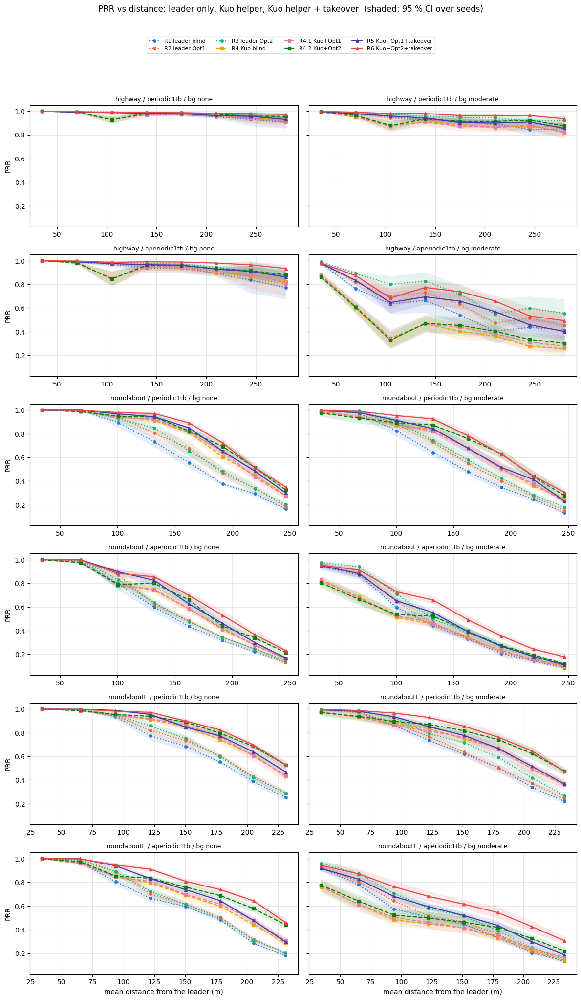

In [38]:
dist_plot(ORDER, 'PRR vs distance: leader only, Kuo helper, Kuo helper + takeover')

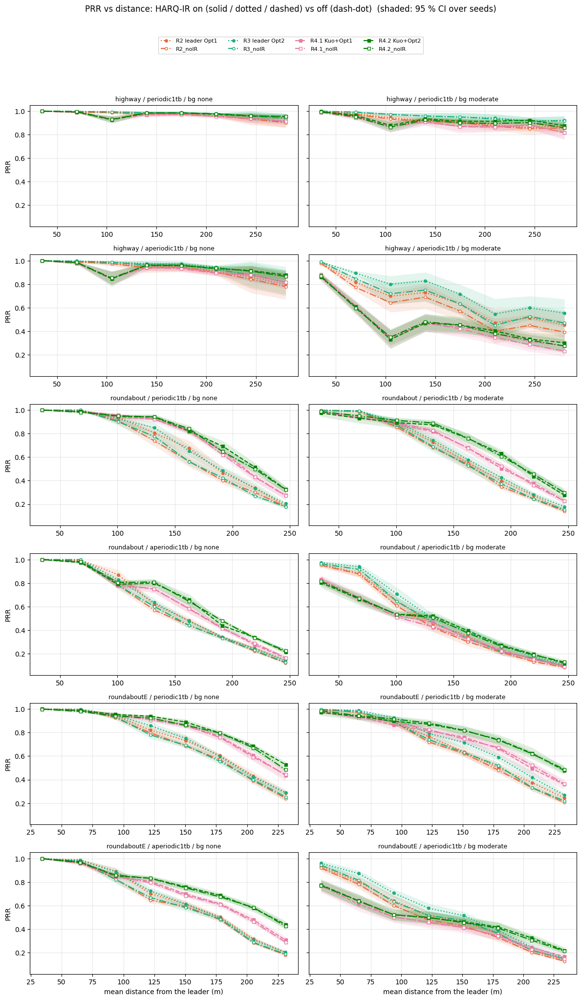

In [39]:
dist_plot(['R2', 'R2_noIR', 'R3', 'R3_noIR', 'R4.1', 'R4.1_noIR', 'R4.2', 'R4.2_noIR'], 'PRR vs distance: HARQ-IR on (solid / dotted / dashed) vs off (dash-dot)')

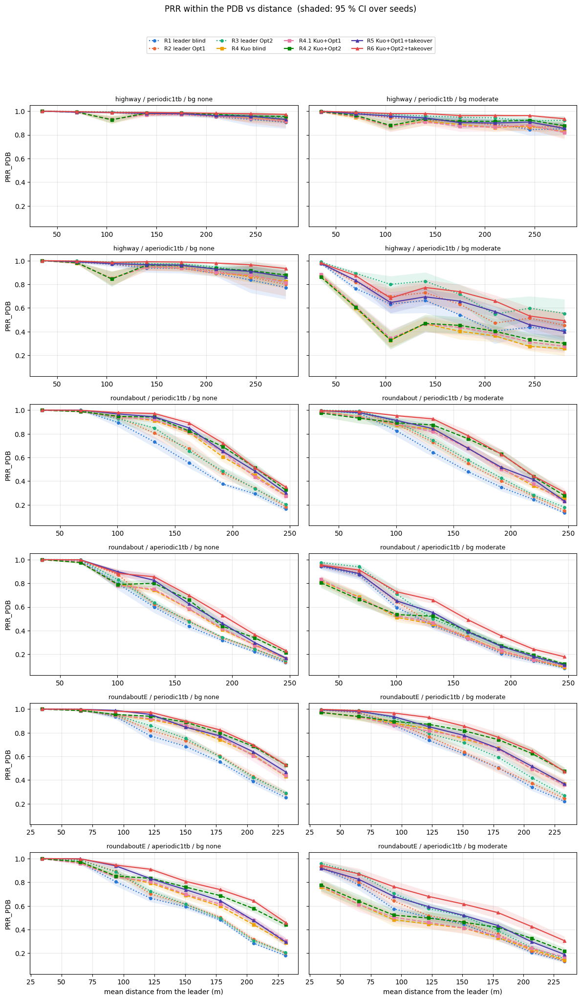

In [40]:
dist_plot(ORDER, 'PRR within the PDB vs distance', metric='prr_pdb')

## PRR versus distance on the corrected data (v2), per load level
The cells above read `OUT` (default `out/remote_full`, the **pre-fix** campaign, invalid for the helper arms). This
section reads the campaigns re-run after the stale-NDI fix (tag `stale-ndi-fix`):
`out/remote_full_v2` (0 and 60 background vehicles, 10 arms) and `out/remote_density_v2` (15, 30, 45 vehicles; arms
R1, R1_bsc, R3, R4, R4.2, R6). One point per member: x = its mean distance from the leader over the KPI window
(roundabouts: the curve only), y = its PRR, mean over 10 seeds, shaded = 95 % CI over seeds.
CBR = `cbr_occupied` of the run (distinct (slot, subchannel) cells used by any vehicle / all cells), averaged over
the runs of the (scenario, traffic, load) cell.

* **Figure set A** (one figure per scenario x traffic): one panel per load level, one line per retransmission method.
* **Figure set B** (one figure per scenario x traffic): one panel per method, one line per load (CBR) level.

In [2]:
# v2 per-member PRR (full + density campaigns)
V2_ROOT = os.environ.get('STUDY_V2_ROOT', os.path.dirname(OUT.rstrip('/')))
V2_DIRS = [os.path.join(V2_ROOT, 'remote_full_v2'), os.path.join(V2_ROOT, 'remote_density_v2')]
NBG_OF = {'none': 0, 'n15': 15, 'n30': 30, 'n45': 45, 'moderate': 60}
SCEN_OF = {'hwy': 'highway', 'rbt': 'roundabout', 'rbtE': 'roundaboutE'}
ARMS_V2 = ['R1', 'R1_bsc', 'R2', 'R3', 'R4', 'R4_bsc', 'R4.1', 'R4.2', 'R5', 'R6']
LABEL_V2 = {'R1': 'R1 leader blind', 'R1_bsc': 'R1_bsc leader blind + comb.', 'R2': 'R2 leader Opt1',
            'R3': 'R3 leader Opt2', 'R4': 'R4 Kuo blind', 'R4_bsc': 'R4_bsc Kuo blind + comb.',
            'R4.1': 'R4.1 Kuo+Opt1', 'R4.2': 'R4.2 Kuo+Opt2', 'R5': 'R5 Kuo+Opt1+takeover',
            'R6': 'R6 Kuo+Opt2+takeover (proposed)'}
# same hue as the arm without combining, dash-dot and open marker for the soft-combining variants
STYLE_V2 = dict(STYLE, **{'R1_bsc': ('#2a78d6', '-.'), 'R4_bsc': ('#eda100', '-.')})
mrows, crows = [], []
for d0 in V2_DIRS:
    for p in sorted(glob.glob(os.path.join(d0, '*', '*_member.csv*'))):
        arm = os.path.basename(os.path.dirname(p))
        tag = os.path.basename(p).split('_member.csv')[0]
        sc, _, tr, bg, s = tag.split('_')
        key = dict(arm=arm, scenario=SCEN_OF[sc], traffic=tr, nbg=NBG_OF[bg], seed=int(s[1:]))
        m = rd(os.path.join(os.path.dirname(p), tag) + '_member.csv')
        m = m[m.member != 'all']
        for _, x in m.iterrows():
            mrows.append(dict(key, member=int(x.member), dist=x.mean_dist_m, prr=x.prr))
        r = rd(os.path.join(os.path.dirname(p), tag) + '_run.csv').iloc[0]
        crows.append(dict(key, cbr=r.cbr_occupied))
MV, CV = pd.DataFrame(mrows), pd.DataFrame(crows)
CBR_V2 = CV.groupby(['scenario', 'traffic', 'nbg']).cbr.mean()
NBGS = sorted(MV.nbg.unique())
print(f'{len(CV)} v2 runs, {len(MV)} (run, member) rows; seeds per (cell, arm): '
      f'{CV.groupby(["scenario", "traffic", "nbg", "arm"]).seed.nunique().min()}-'
      f'{CV.groupby(["scenario", "traffic", "nbg", "arm"]).seed.nunique().max()}')
display(CBR_V2.unstack('nbg').round(3))

2280 v2 runs, 18240 (run, member) rows; seeds per (cell, arm): 10-10


nbg                          0      15     30     45     60
scenario    traffic                                        
highway     aperiodic1tb  0.012  0.244  0.424  0.585  0.699
            periodic1tb   0.004  0.239  0.421  0.583  0.698
roundabout  aperiodic1tb  0.013  0.232  0.422  0.575  0.689
            periodic1tb   0.005  0.226  0.419  0.573  0.688
roundaboutE aperiodic1tb  0.013  0.233  0.424  0.576  0.689
            periodic1tb   0.005  0.227  0.420  0.574  0.688

In [3]:
def _dist_line(ax, d, col, ls, label, mfc=None):
    g = mean_ci(d, ['dist', 'prr'], 'member').sort_values('dist')
    if not len(g):
        return
    ax.plot(g.dist, g.prr, ls, color=col, lw=1.6, marker=MARK.get(ls, 'D'), ms=4,
            mfc=mfc or col, label=label)
    ax.fill_between(g.dist, g.prr - g.prr_ci, g.prr + g.prr_ci, color=col, alpha=.12, lw=0)

def prr_dist_by_method(sc, tr):
    """Set A: one panel per load level, one line per method."""
    d = MV[(MV.scenario == sc) & (MV.traffic == tr)]
    fig, axes = plt.subplots(1, len(NBGS), figsize=(3.4 * len(NBGS), 3.6), sharey=True, squeeze=False)
    for ax, nbg in zip(axes[0], NBGS):
        x = d[d.nbg == nbg]
        for arm in ARMS_V2:
            col, ls = STYLE_V2[arm]
            _dist_line(ax, x[x.arm == arm], col, ls, LABEL_V2[arm], mfc='white' if arm.endswith('_bsc') else None)
        ax.set_title(f'{nbg} vehicles, CBR {CBR_V2[(sc, tr, nbg)]:.2f}', fontsize=9)
        ax.set_xlabel('mean distance from the leader (m)'); ax.grid(alpha=.3)
    axes[0, 0].set_ylabel('PRR')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.03))
    fig.suptitle(f'{sc} / {tr}: PRR vs distance per method (15-45 vehicles: 6 arms only; shaded: 95 % CI)', y=1.1)
    fig.tight_layout(); plt.show()

def prr_dist_by_load(sc, tr):
    """Set B: one panel per method, one line per load (CBR) level."""
    d = MV[(MV.scenario == sc) & (MV.traffic == tr)]
    cmap = plt.cm.viridis_r
    cols = {n: cmap(0.12 + 0.8 * i / (len(NBGS) - 1)) for i, n in enumerate(NBGS)}
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.6), sharey=True, sharex=True)
    for ax, arm in zip(axes.flat, ARMS_V2):
        x = d[d.arm == arm]
        for nbg in NBGS:
            _dist_line(ax, x[x.nbg == nbg], cols[nbg], '-',
                       f'{nbg} vehicles (CBR {CBR_V2[(sc, tr, nbg)]:.2f})')
        ax.set_title(LABEL_V2[arm], fontsize=9); ax.grid(alpha=.3)
    for ax in axes[1]: ax.set_xlabel('mean distance from the leader (m)')
    for ax in axes[:, 0]: ax.set_ylabel('PRR')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f'{sc} / {tr}: PRR vs distance per load level (R2, R4_bsc, R4.1, R5: 0 and 60 vehicles only)', y=1.03)
    fig.tight_layout(); plt.show()

### Set A: methods compared, one panel per load level

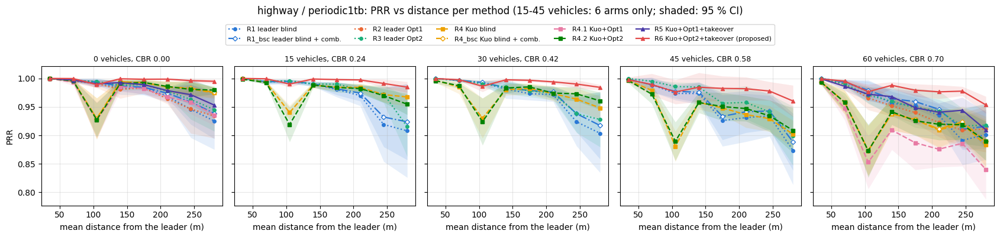

In [4]:
prr_dist_by_method('highway', 'periodic1tb')

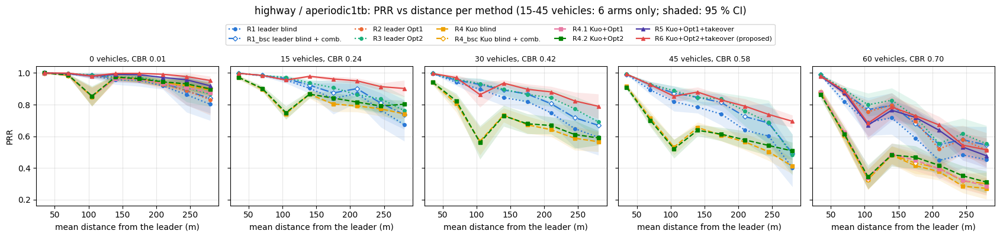

In [5]:
prr_dist_by_method('highway', 'aperiodic1tb')

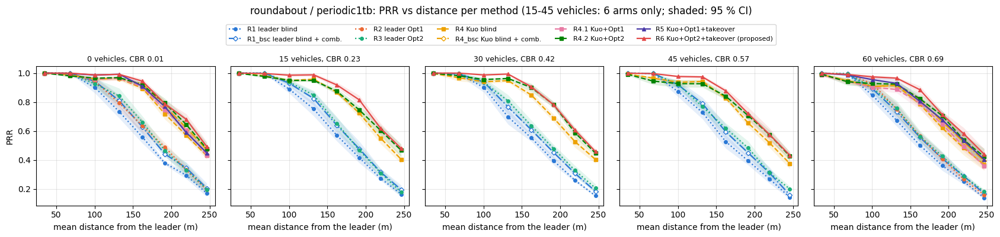

In [6]:
prr_dist_by_method('roundabout', 'periodic1tb')

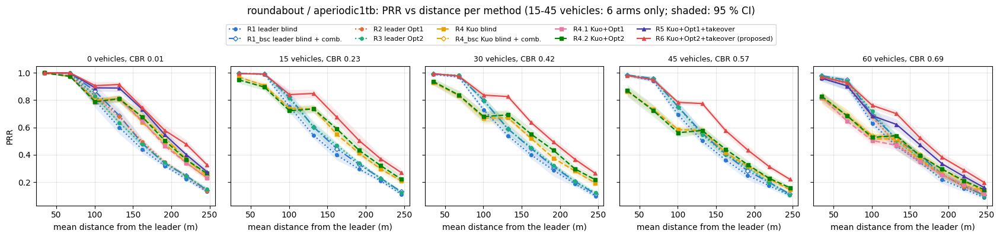

In [7]:
prr_dist_by_method('roundabout', 'aperiodic1tb')

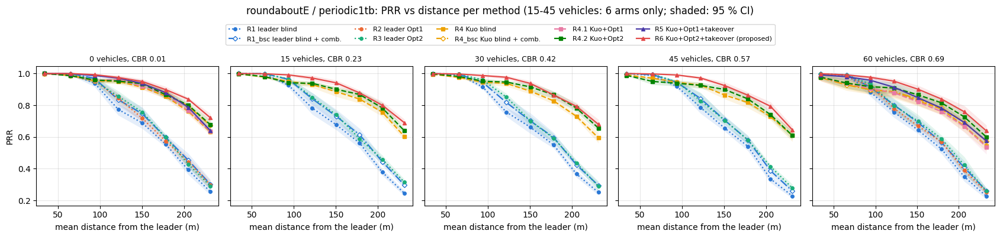

In [8]:
prr_dist_by_method('roundaboutE', 'periodic1tb')

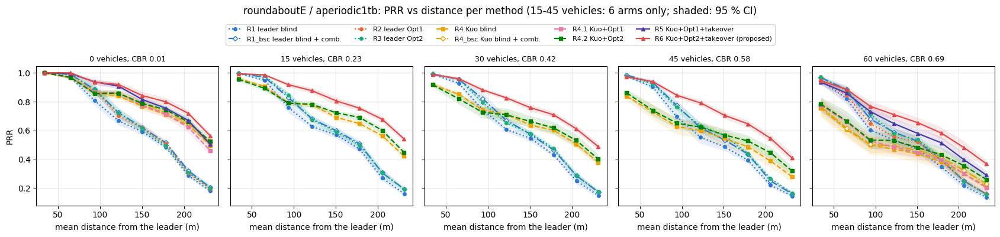

In [9]:
prr_dist_by_method('roundaboutE', 'aperiodic1tb')

### Set B: load levels compared, one panel per method

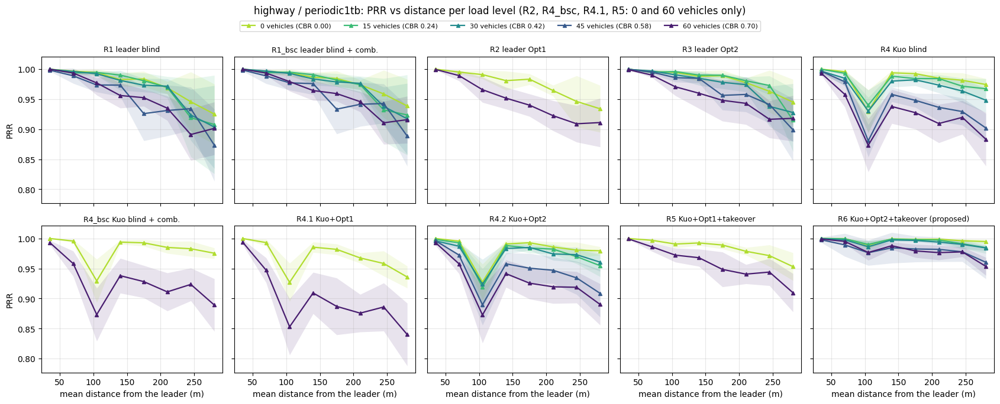

In [10]:
prr_dist_by_load('highway', 'periodic1tb')

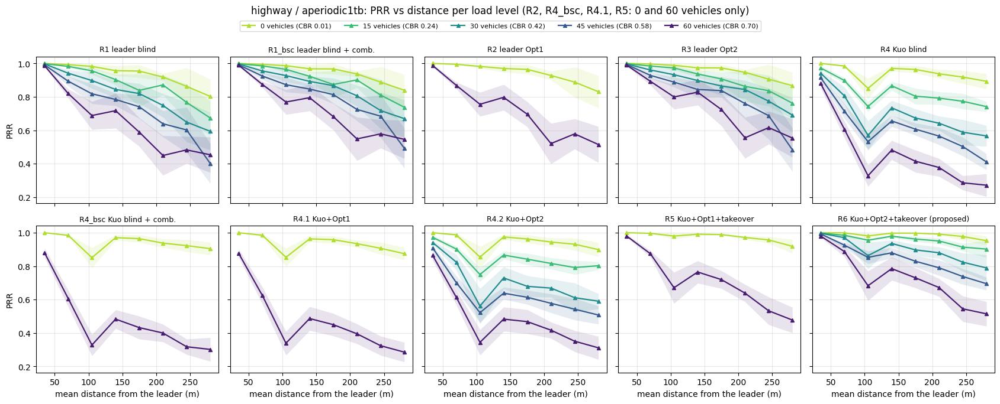

In [11]:
prr_dist_by_load('highway', 'aperiodic1tb')

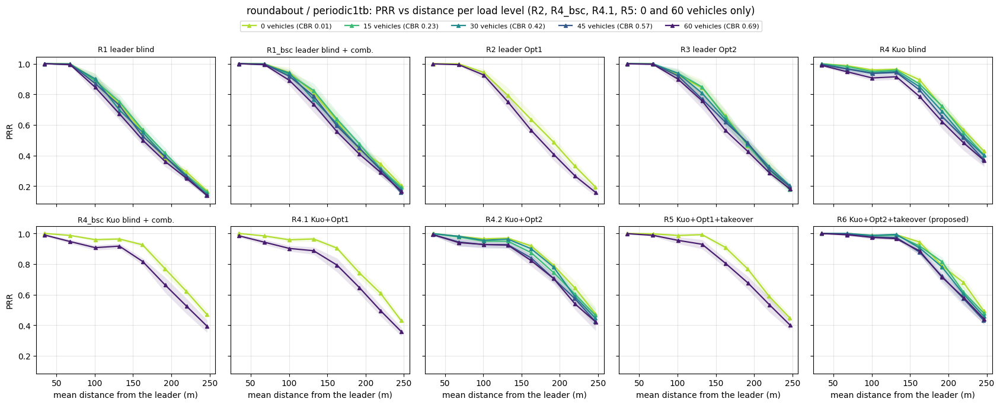

In [12]:
prr_dist_by_load('roundabout', 'periodic1tb')

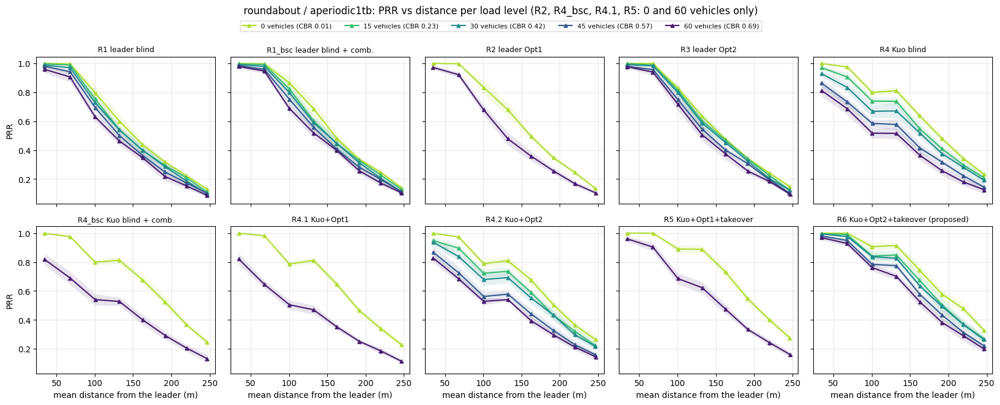

In [13]:
prr_dist_by_load('roundabout', 'aperiodic1tb')

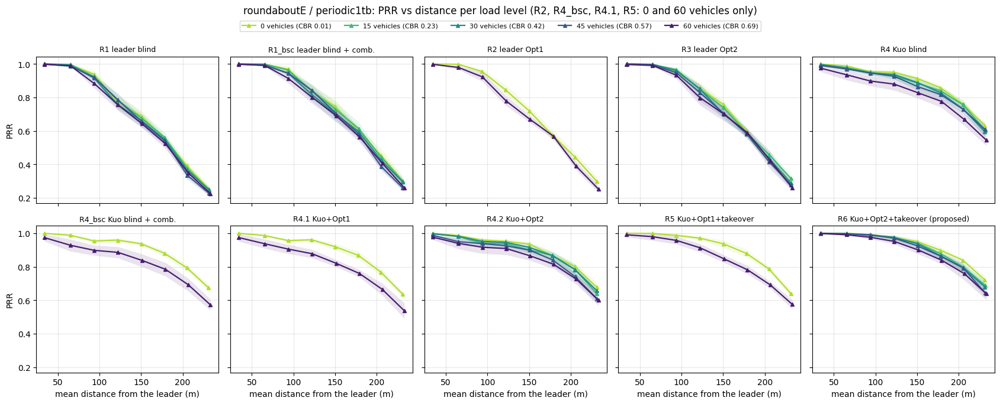

In [14]:
prr_dist_by_load('roundaboutE', 'periodic1tb')

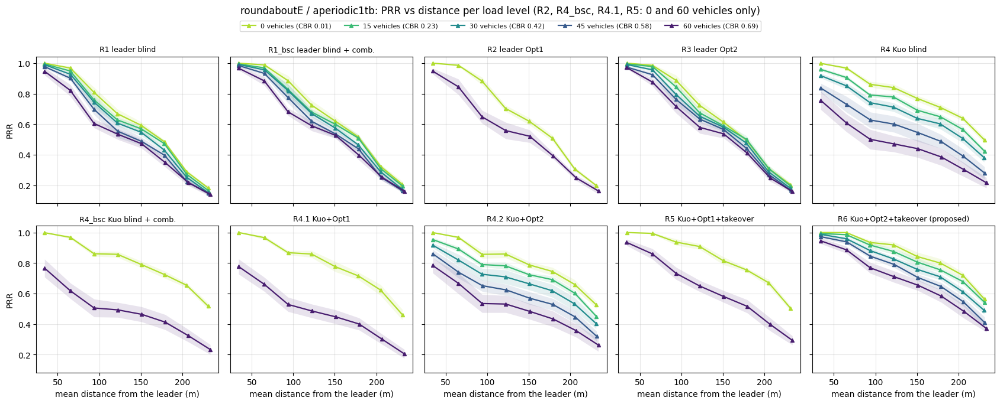

In [15]:
prr_dist_by_load('roundaboutE', 'aperiodic1tb')

## Summary per cell and arm

In [41]:

agg = R.groupby(CELLS + ['arm']).agg(seeds=('seed', 'nunique'), prr=('prr', 'mean'), prr_worst=('prr_worst', 'mean'),
        prr_pdb=('prr_pdb', 'mean'), prr_pdb_worst=('prr_pdb_worst', 'mean'), tx_per_pkt=('tx_per_pkt', 'mean'), resv_per_pkt=('resv_per_pkt', 'mean'),
        cbr_platoon=('cbr_platoon', 'mean'), cbr_total=('cbr_total', 'mean'), psfch_per_tb=('psfch_per_tb', 'mean')).reset_index()
AGGCI = mean_ci(R, ['prr', 'prr_worst', 'prr_pdb', 'prr_pdb_worst', 'cbr_platoon'], CELLS + ['arm'])
main = agg[agg.arm.isin(ORDER)].copy()
main['arm'] = pd.Categorical(main.arm, ORDER)
main.sort_values(CELLS + ['arm']).round(3)


,scenario,traffic,bg,arm,seeds,prr,prr_worst,prr_pdb,prr_pdb_worst,tx_per_pkt,resv_per_pkt,cbr_platoon,cbr_total,psfch_per_tb
0,highway,aperiodic1tb,moderate,R1,10,0.604,0.304,0.604,0.304,14.541,71.833,0.015,0.987,0.000
2,highway,aperiodic1tb,moderate,R2,10,0.661,0.336,0.661,0.336,12.273,71.625,0.012,0.984,4.716
4,highway,aperiodic1tb,moderate,R3,10,0.741,0.399,0.741,0.399,13.944,70.959,0.014,0.986,18.326
6,highway,aperiodic1tb,moderate,R4,10,0.446,0.226,0.446,0.226,7.962,72.965,0.008,0.980,0.000
7,highway,aperiodic1tb,moderate,R4.1,10,0.464,0.245,0.464,0.245,7.020,72.947,0.007,0.979,3.133
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,roundaboutE,periodic1tb,none,R4,10,0.811,0.432,0.811,0.432,5.704,5.892,0.006,0.006,0.000
161,roundaboutE,periodic1tb,none,R4.1,10,0.816,0.436,0.816,0.436,4.065,5.892,0.004,0.004,2.193
163,roundaboutE,periodic1tb,none,R4.2,10,0.848,0.527,0.848,0.527,4.735,5.892,0.005,0.005,11.002
166,roundaboutE,periodic1tb,none,R5,10,0.834,0.469,0.834,0.469,4.217,5.892,0.004,0.004,2.279


## Spectrum and CBR savings
Savings against the blind counterpart of the same family (leader arms vs R1, helper arms vs R4): transmitted subchannel-slots (interference / energy), platoon CBR, and reserved (announced) subchannel-slots (capacity for sensing UEs).

In [42]:

ref = {'R1': 'R1', 'R2': 'R1', 'R3': 'R1', 'R4': 'R4', 'R4.1': 'R4', 'R4.2': 'R4', 'R5': 'R4', 'R6': 'R4'}
rows = []
for (sc, tr, bg), g in agg[agg.arm.isin(ORDER)].groupby(CELLS):
    g = g.set_index('arm')
    for arm in ORDER:
        if arm in g.index and ref[arm] in g.index:
            b = g.loc[ref[arm]]
            rows.append(dict(scenario=sc, traffic=tr, bg=bg, arm=arm, vs=ref[arm],
                cbr_platoon=g.loc[arm, 'cbr_platoon'],
                cbr_saving_pct=100 * (1 - g.loc[arm, 'cbr_platoon'] / b.cbr_platoon),
                tx_saving_pct=100 * (1 - g.loc[arm, 'tx_per_pkt'] / b.tx_per_pkt),
                resv_saving_pct=100 * (1 - g.loc[arm, 'resv_per_pkt'] / b.resv_per_pkt),
                d_prr=g.loc[arm, 'prr'] - b.prr, d_prr_worst=g.loc[arm, 'prr_worst'] - b.prr_worst))
CB = pd.DataFrame(rows)
CB.round(3)


,scenario,traffic,bg,arm,vs,cbr_platoon,cbr_saving_pct,tx_saving_pct,resv_saving_pct,d_prr,d_prr_worst
0,highway,aperiodic1tb,moderate,R1,R1,0.015,0.000,0.000,0.000,0.000,0.000
1,highway,aperiodic1tb,moderate,R2,R1,0.012,15.606,15.593,0.289,0.057,0.033
2,highway,aperiodic1tb,moderate,R3,R1,0.014,4.112,4.105,1.216,0.137,0.095
3,highway,aperiodic1tb,moderate,R4,R4,0.008,0.000,0.000,0.000,0.000,0.000
4,highway,aperiodic1tb,moderate,R4.1,R4,0.007,11.820,11.824,0.024,0.018,0.019
...,...,...,...,...,...,...,...,...,...,...,...
91,roundaboutE,periodic1tb,none,R4,R4,0.006,0.000,0.000,0.000,0.000,0.000
92,roundaboutE,periodic1tb,none,R4.1,R4,0.004,28.739,28.739,0.000,0.004,0.004
93,roundaboutE,periodic1tb,none,R4.2,R4,0.005,16.999,16.999,0.000,0.036,0.095
94,roundaboutE,periodic1tb,none,R5,R4,0.004,26.065,26.065,0.000,0.022,0.037


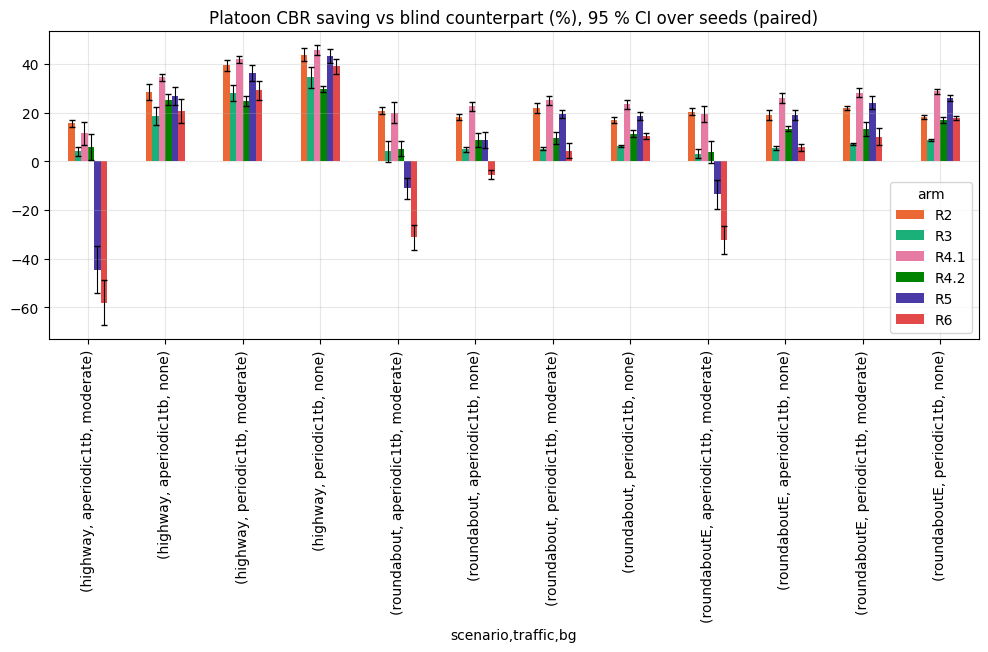

In [43]:
# paired per seed: saving of the arm vs its blind counterpart in the same seed
Rs = R[R.arm.isin(ORDER)].set_index(CELLS + ['seed', 'arm']).cbr_platoon
pr = [dict(scenario=sc, traffic=tr, bg=bg, seed=sd, arm=a, s=100 * (1 - v / Rs.get((sc, tr, bg, sd, ref[a]), np.nan)))
      for (sc, tr, bg, sd, a), v in Rs.items() if a not in ('R1', 'R4')]
pc = mean_ci(pd.DataFrame(pr), ['s'], CELLS + ['arm'])
arms = [a for a in ORDER if a not in ('R1', 'R4')]
p = pc.pivot_table(index=CELLS, columns='arm', values='s')[arms]
e = pc.pivot_table(index=CELLS, columns='arm', values='s_ci')[arms]
p.plot.bar(yerr=e, capsize=2, figsize=(12, 4), color=[STYLE[a][0] for a in arms], error_kw=dict(lw=.8),
           title='Platoon CBR saving vs blind counterpart (%), 95 % CI over seeds (paired)')
plt.grid(alpha=.3); plt.show()

## Spectrum use by component
Each bar is the total spectrum one retransmission method uses per generated packet in one scenario, stacked by what occupies it.
Unit: PRB x symbols (PSSCH+PSCCH of a transmission = its PRBs x 9 symbols; one PSFCH resource = 1 PRB x 2 symbols).
Feedback: Option 1 counts one shared NACK resource per transmission with >= 1 member NACK (the R5 helper NACKs on a dedicated
resource); Option 2 counts one resource per ACK / NACK (re-ACKs included; Option-2 ACKs are whole-run counts scaled to the KPI window).
In R4.1 / R4.2 the helper is a plain member, so its feedback is in *members feedback*.

In [44]:

# Spectrum use per generated packet, split by what occupies it (PRB x symbols, KPI window).
# PSSCH (+PSCCH) of a transmission: rb_len PRBs x 9 symbols (every slot carries PSFCH: psfchPeriod 1).
# PSFCH: 1 PRB x 2 symbols per resource. Option 1: one shared NACK resource per transmission that drew
# >= 1 member NACK (the R5 helper NACKs on its own resource); Option 2: one resource per ACK / NACK.
PSSCH_SYM, PSFCH_RE = 9, 2
OPT = {'R1': 0, 'R2': 1, 'R3': 2, 'R4': 0, 'R4.1': 1, 'R4.2': 2, 'R5': 1, 'R6': 2}
COMP = ['leader initial', 'leader retx', 'leader takeover (helper NACK)', 'leader takeover (fallback)',
        'helper relay', 'helper feedback (NACK)', 'members feedback']
CCOL = ['#4c72b0', '#8fa9d6', '#dd8452', '#c44e52', '#55a868', '#937860', '#8172b3']

def helper_at(hs, harq, t):
    if hs is None:
        return None
    h = hs[(hs.harq_id == harq) & (hs.t_ndi <= t + 1e-9)]
    return int(h.applied.iloc[-1]) if len(h) else None

comp_rows = []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    if arm not in OPT:
        continue
    for p in sorted(glob.glob(armdir + '*_run.csv*')):
        tag = os.path.basename(p).split('_run.csv')[0]
        pre = os.path.join(armdir, tag)
        r = rd(pre + '_run.csv').iloc[0]
        k0, k1 = r.kpi_start, r.kpi_end
        win = lambda df: df[(df.t >= k0) & (df.t < k1)] if df is not None and len(df) else df
        ltx, htx = win(rd(pre + '_ltx.csv')), win(rd(pre + '_htx.csv'))
        nack, hs = win(rd(pre + '_nack.csv')), rd(pre + '_hsel.csv')
        c = dict.fromkeys(COMP, 0.0)
        if ltx is not None and len(ltx):
            re_ = ltx.rb_len * PSSCH_SYM
            org = ltx.origin if 'origin' in ltx else 0 * ltx.ndi
            c['leader initial'] = re_[ltx.ndi == 1].sum()
            c['leader retx'] = re_[(ltx.ndi == 0) & (org == 0)].sum()
            c['leader takeover (helper NACK)'] = re_[org == 1].sum()
            c['leader takeover (fallback)'] = re_[org == 2].sum()
        if htx is not None and len(htx):
            c['helper relay'] = (htx.rb_len * PSSCH_SYM).sum()
        takeover = arm in ('R5', 'R6')
        n_help = n_mem = 0
        occ = set()
        if nack is not None and len(nack):
            for x in nack.itertuples():
                h = helper_at(hs, x.harq_id, x.t) if takeover else None
                if takeover and x.member == h:
                    n_help += 1
                else:
                    n_mem += 1
                    occ.add((x.tx_rnti, x.harq_id, round(x.t / SLOT)))
        if OPT[arm] == 1:
            c['members feedback'] = PSFCH_RE * len(occ)
        elif OPT[arm] == 2:
            # ACKs are only counted for the whole run: scale to the KPI window by the share of TBs
            all_ltx = rd(pre + '_ltx.csv')
            frac = (ltx.ndi == 1).sum() / max((all_ltx.ndi == 1).sum(), 1)
            c['members feedback'] = PSFCH_RE * (n_mem + r.explicit_ack_rx * frac)
        c['helper feedback (NACK)'] = PSFCH_RE * n_help
        cc = cell_of(tag)
        comp_rows.append(dict(arm=arm, **cc, **{k: v / r.pkts for k, v in c.items()}))
SP = pd.DataFrame(comp_rows).groupby(CELLS + ['arm'])[COMP].mean().reset_index()
SPT = mean_ci(pd.DataFrame(comp_rows).assign(total=lambda x: x[COMP].sum(axis=1)), ['total'], CELLS + ['arm'])

SUBCH_SLOT = 10 * PSSCH_SYM  # one subchannel (10 PRB) over the PSSCH symbols of a slot

def spectrum_plot(cols, title, ylabel, scale=1.0, prr=False):
    prr_handles = ([], [])
    cells = SP[CELLS].drop_duplicates().sort_values(CELLS).values.tolist()
    nr = -(-len(cells) // 4)   # one row per scenario (4 cells: traffic x bg)
    fig, axes = plt.subplots(nr, 4, figsize=(17, 4.25 * nr), sharey=False, squeeze=False)
    for ax, (sc, tr, bg) in zip(axes.flat, cells):
        d = SP[(SP.scenario == sc) & (SP.traffic == tr) & (SP.bg == bg)].set_index('arm').reindex(
            [a for a in ORDER if a in set(SP.arm)])
        d = d[COMP] / scale
        bottom = np.zeros(len(d))
        for comp, col in zip(COMP, CCOL):
            if comp in cols:
                ax.bar(d.index, d[comp].fillna(0), bottom=bottom, color=col, label=comp, edgecolor='white', lw=.5)
                bottom += d[comp].fillna(0).values
        if set(cols) == set(COMP):   # 95 % CI of the stacked total (all components)
            e = SPT[(SPT.scenario == sc) & (SPT.traffic == tr) & (SPT.bg == bg)].set_index('arm').reindex(d.index)
            ax.errorbar(np.arange(len(d)), bottom, yerr=e.total_ci.values / scale, fmt='none', ecolor='k',
                        elinewidth=.8, capsize=2)
        for i, tot in enumerate(bottom):
            ax.text(i, tot, f'{tot:.0f}' if tot >= 100 else (f'{tot:.1f}' if tot >= 1 else f'{tot:.3f}'),
                    ha='center', va='bottom', fontsize=7)
        if prr:
            q = agg[(agg.scenario == sc) & (agg.traffic == tr) & (agg.bg == bg)].set_index('arm').reindex(d.index)
            ax2 = ax.twinx()
            x = np.arange(len(d))
            pm, pw, tag = (q.prr_pdb, q.prr_pdb_worst, 'PRR within PDB') if prr == 'pdb' else (q.prr, q.prr_worst, 'PRR')
            qc = AGGCI[(AGGCI.scenario == sc) & (AGGCI.traffic == tr) & (AGGCI.bg == bg)].set_index('arm').reindex(d.index)
            em, ew = (qc.prr_pdb_ci, qc.prr_pdb_worst_ci) if prr == 'pdb' else (qc.prr_ci, qc.prr_worst_ci)
            ax2.errorbar(x, pm, yerr=em, fmt='k-o', ms=4, lw=1.2, capsize=2, elinewidth=.8, label=f'{tag} group (mean)')
            ax2.errorbar(x, pw, yerr=ew, fmt='k--^', ms=4, lw=1.2, mfc='white', capsize=2, elinewidth=.8,
                         label=f'{tag} worst member')
            ax2.set_ylim(0, 1.05)
            ax2.tick_params(labelsize=8)
            if (sc, tr, bg) == tuple(cells[-1]) or ax in axes[:, -1]:
                ax2.set_ylabel('PRR')
            prr_handles = ax2.get_legend_handles_labels()
        ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.grid(axis='y', alpha=.3)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    h, l = axes.flat[0].get_legend_handles_labels()
    h, l = h + prr_handles[0], l + prr_handles[1]
    fig.legend(h, l, loc='upper center', ncol=min(len(h), 9), fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06); fig.tight_layout(); plt.show()


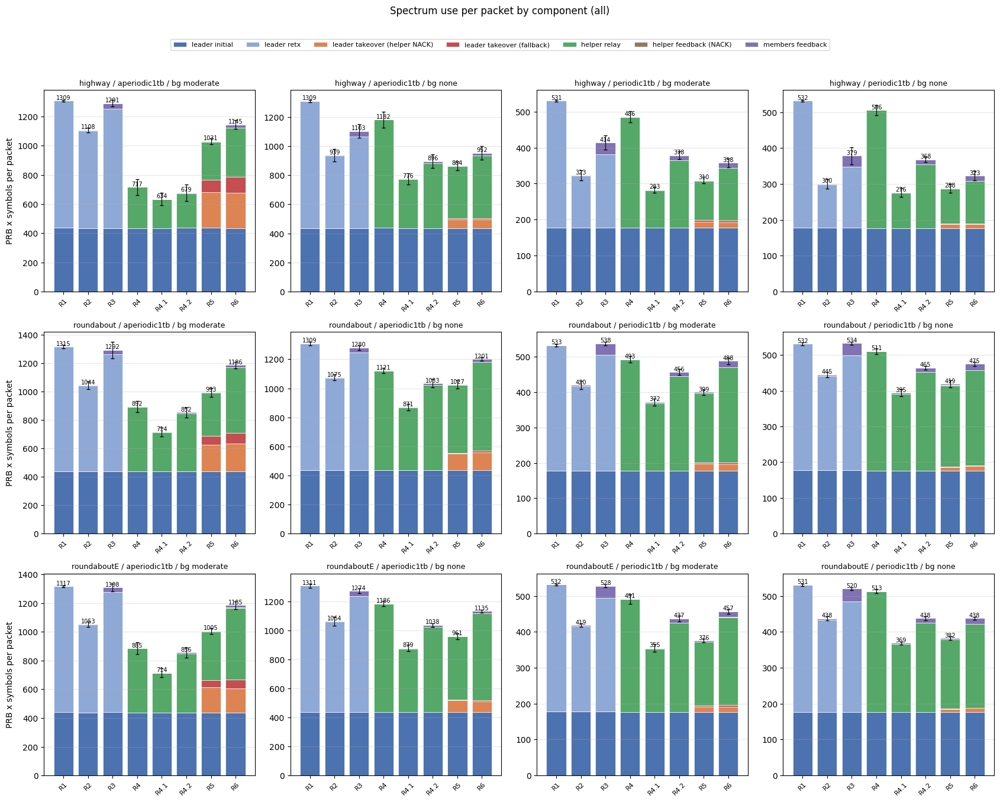

In [45]:
spectrum_plot(COMP, 'Spectrum use per packet by component (all)', 'PRB x symbols per packet')

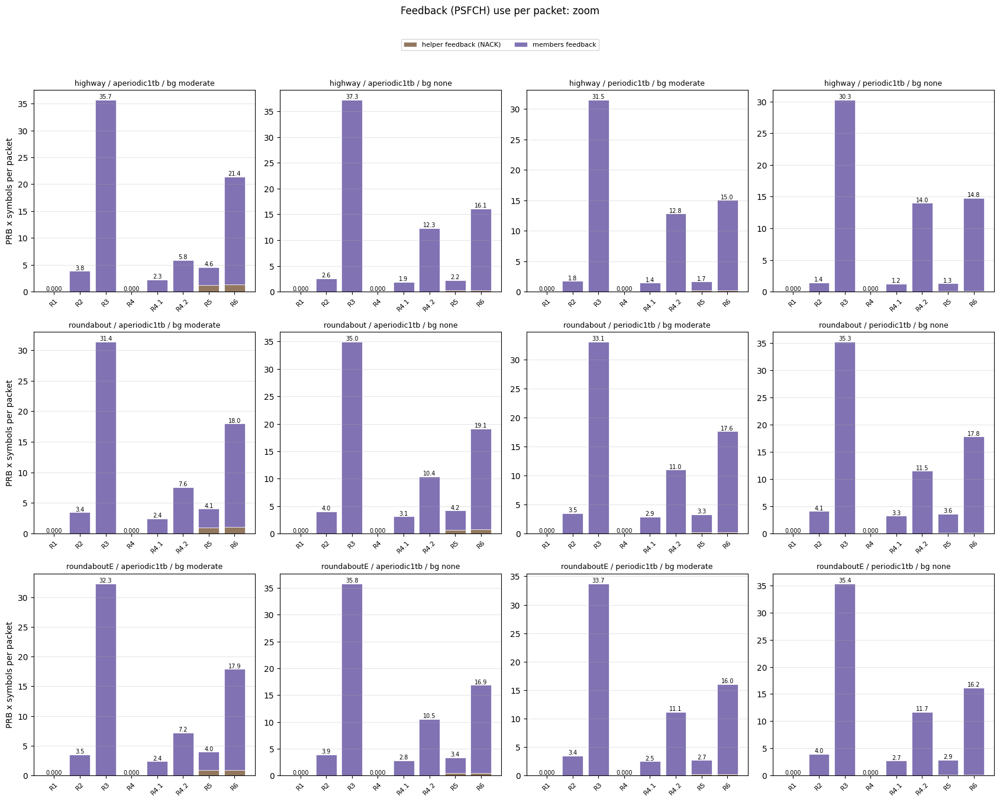

In [46]:
spectrum_plot(['helper feedback (NACK)', 'members feedback'], 'Feedback (PSFCH) use per packet: zoom', 'PRB x symbols per packet')

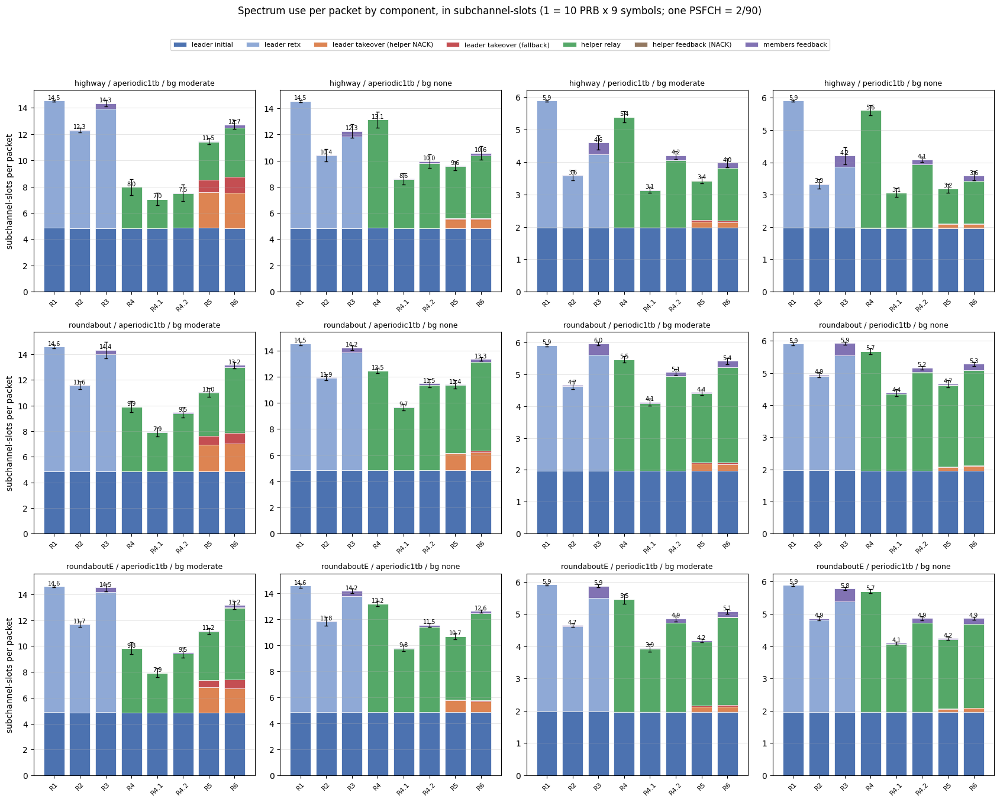

In [47]:
spectrum_plot(COMP, 'Spectrum use per packet by component, in subchannel-slots (1 = 10 PRB x 9 symbols; one PSFCH = 2/90)', 'subchannel-slots per packet', scale=SUBCH_SLOT)

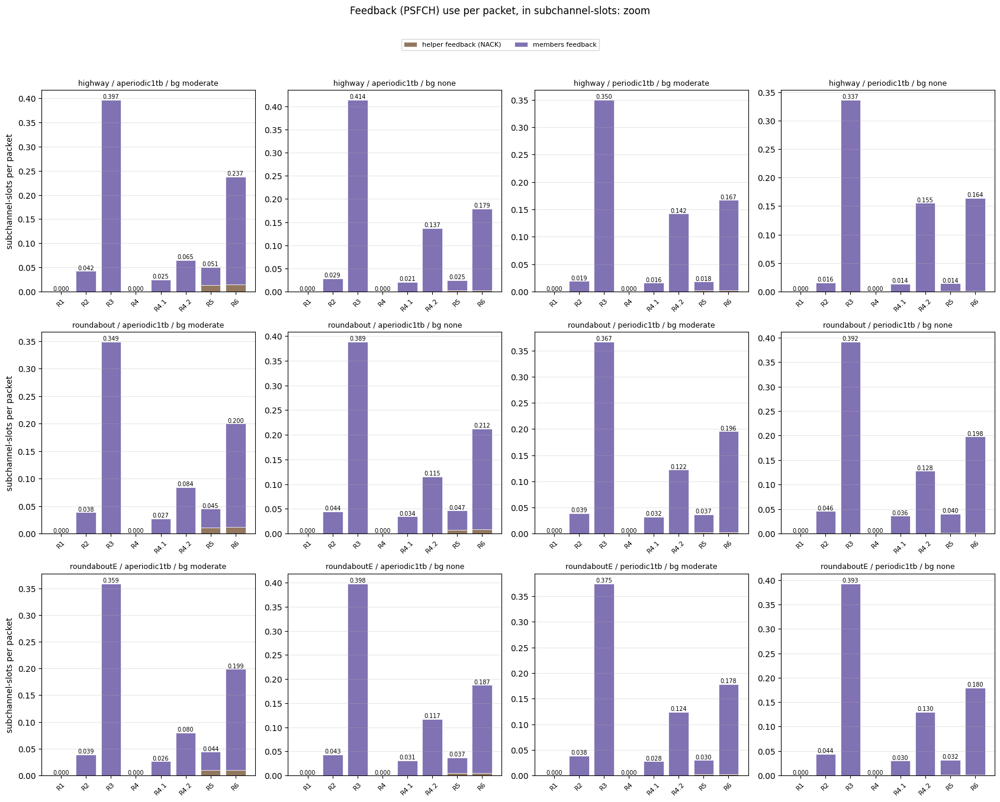

In [48]:
spectrum_plot(['helper feedback (NACK)', 'members feedback'], 'Feedback (PSFCH) use per packet, in subchannel-slots: zoom', 'subchannel-slots per packet', scale=SUBCH_SLOT)

### Spectrum and PRR together (script `plot_spectrum_prr.py`)
Rendered by the standalone script, which also saves `figures/spectrum_prr_{prb,subch}_<profile>.png`.

1680 runs, seeds per cell: 10-10


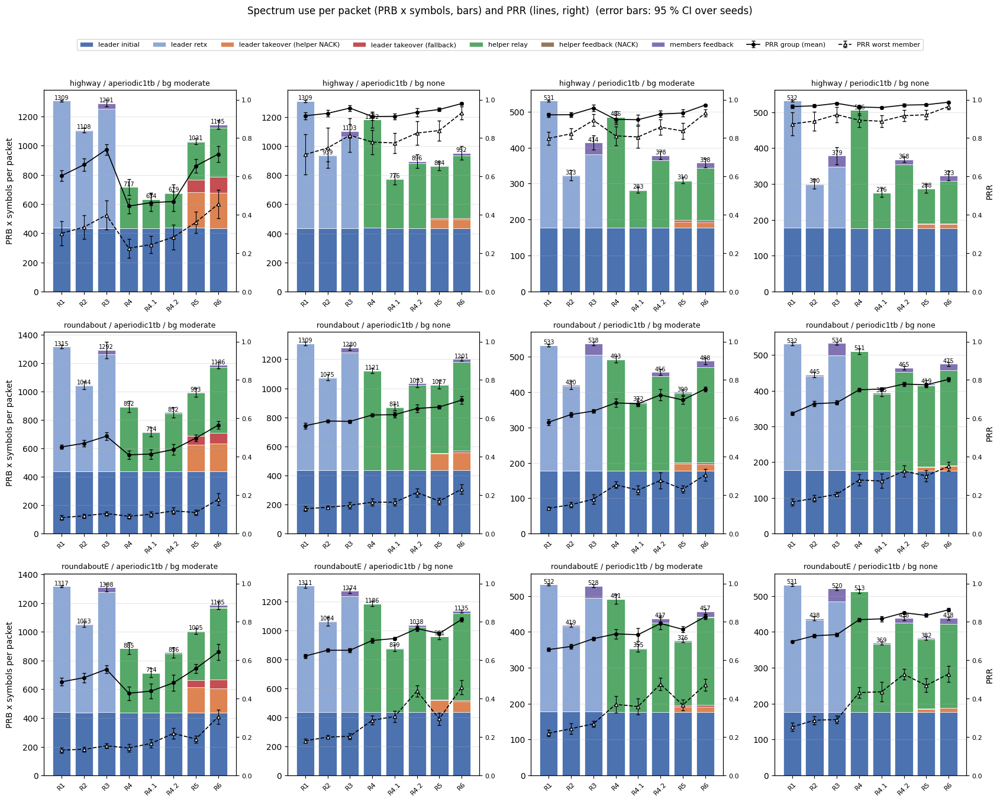

/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/figures/spectrum_prr_prb_remote_full.png


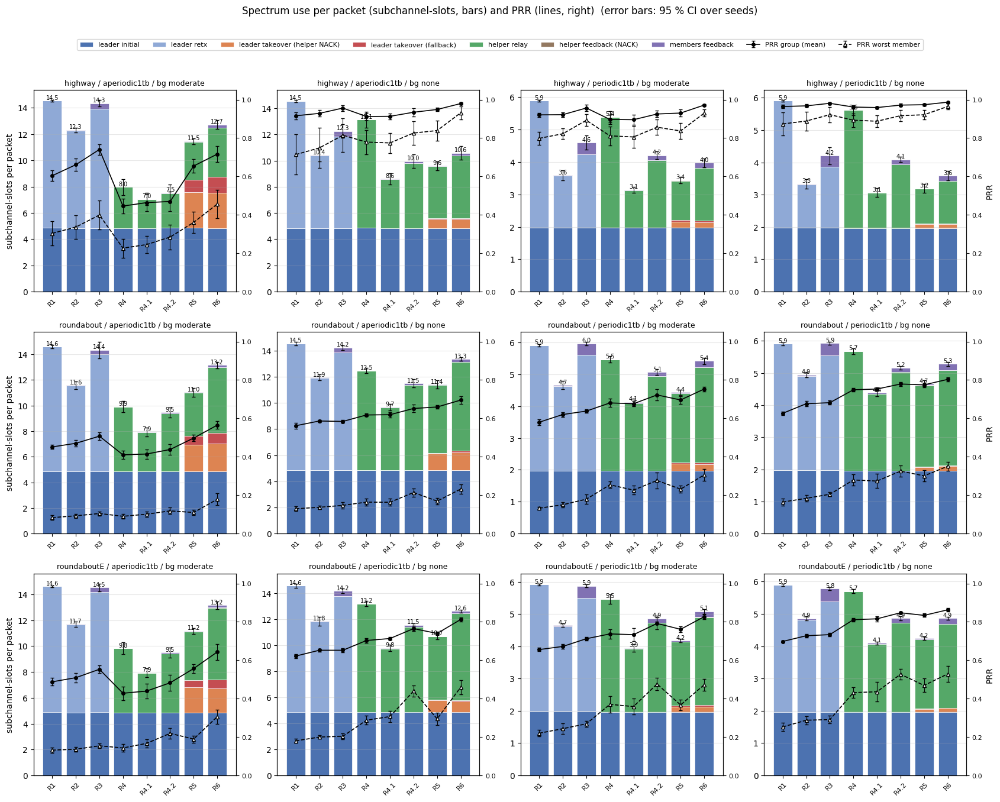

/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/figures/spectrum_prr_subch_remote_full.png


In [49]:
%run scripts/plot_spectrum_prr.py --profile remote_full --out {OUT} --show

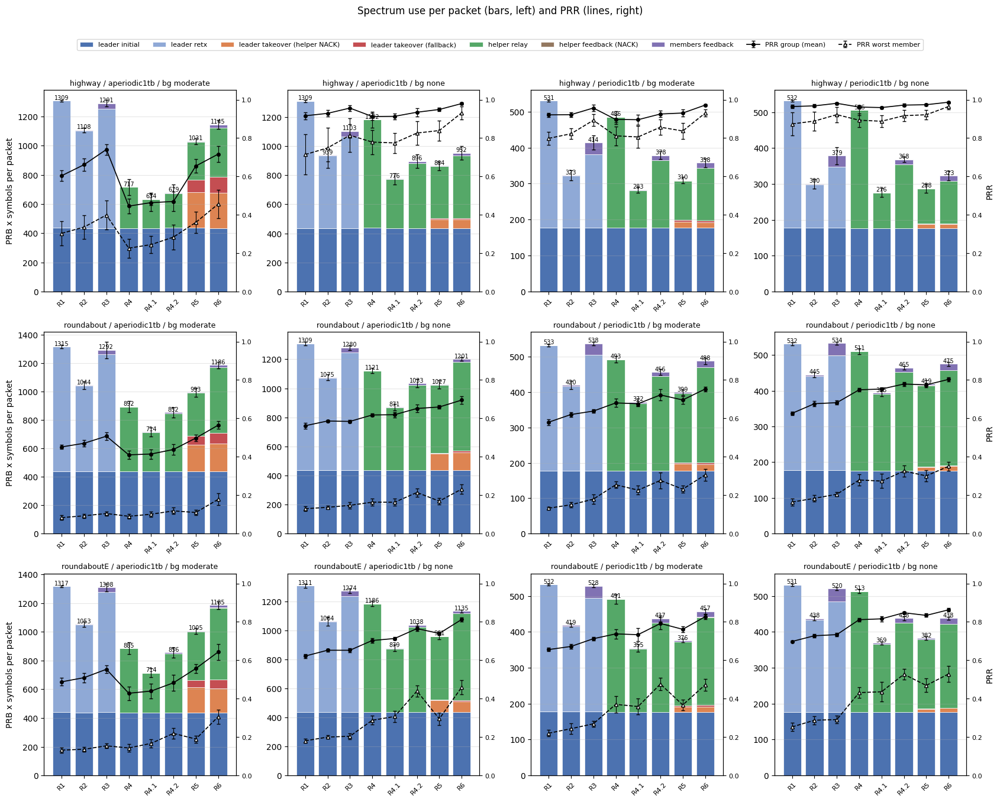

In [50]:
spectrum_plot(COMP, 'Spectrum use per packet (bars, left) and PRR (lines, right)', 'PRB x symbols per packet', prr=True)

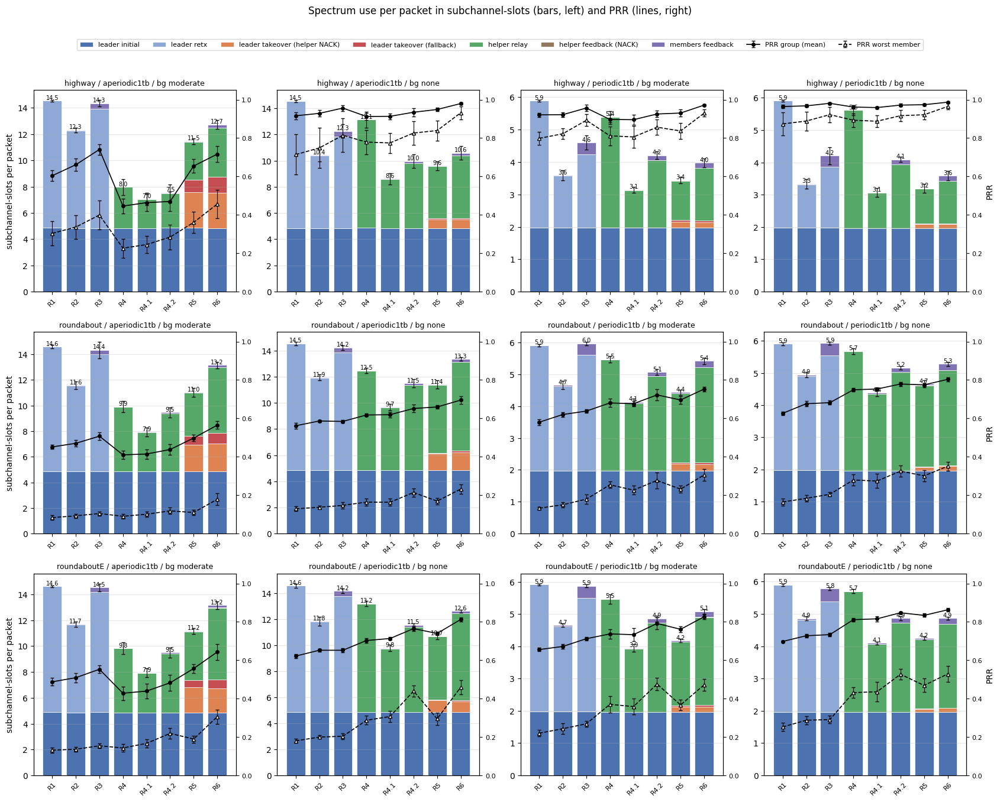

In [51]:
spectrum_plot(COMP, 'Spectrum use per packet in subchannel-slots (bars, left) and PRR (lines, right)', 'subchannel-slots per packet', scale=SUBCH_SLOT, prr=True)

Same two figures with **PRR within the PDB** (packets delivered after the PDB count as lost).

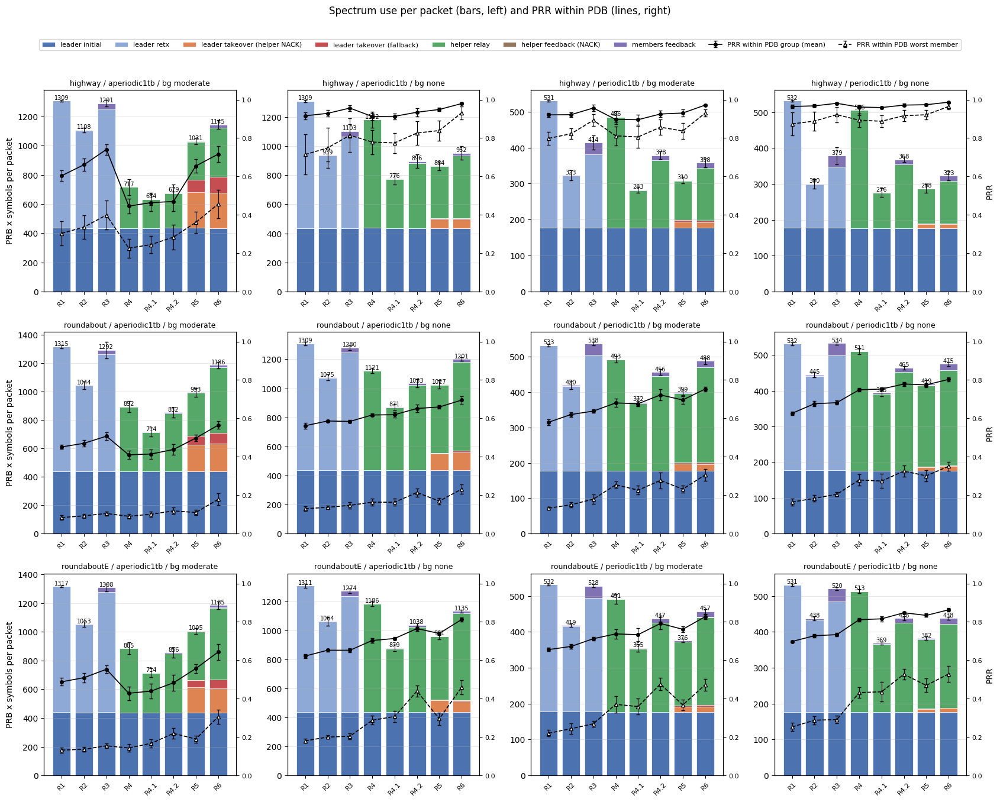

In [52]:
spectrum_plot(COMP, 'Spectrum use per packet (bars, left) and PRR within PDB (lines, right)', 'PRB x symbols per packet', prr='pdb')

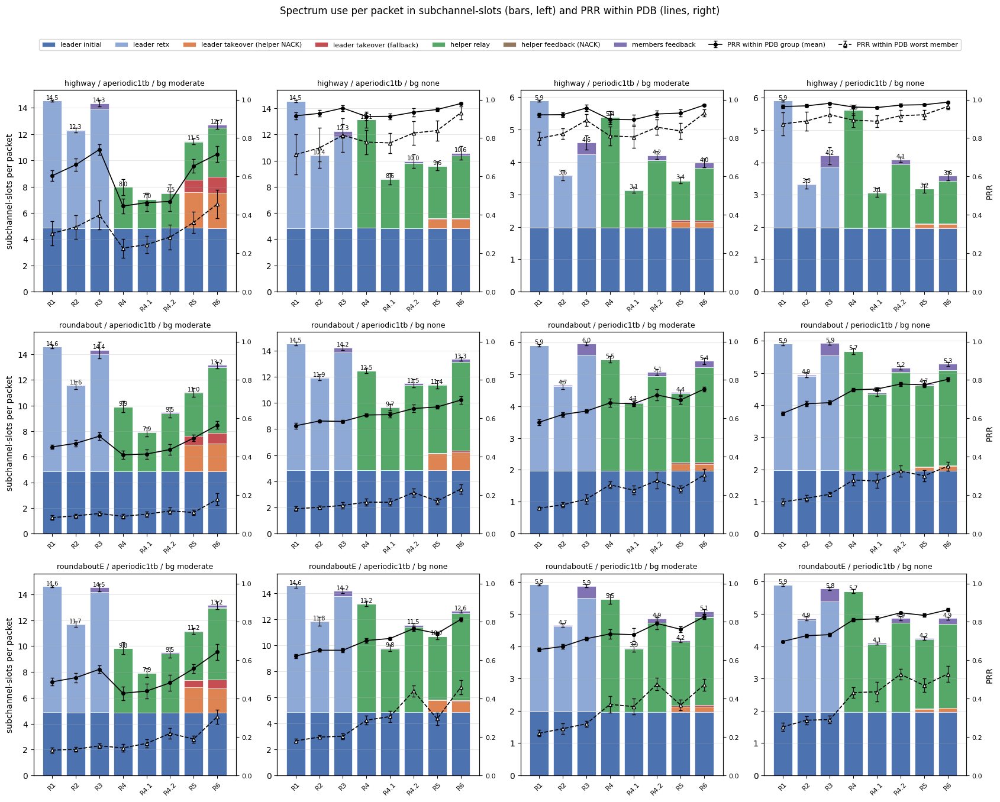

In [53]:
spectrum_plot(COMP, 'Spectrum use per packet in subchannel-slots (bars, left) and PRR within PDB (lines, right)', 'subchannel-slots per packet', scale=SUBCH_SLOT, prr='pdb')

In [54]:
SP.assign(total=SP[COMP].sum(axis=1)).round(1)

,scenario,traffic,bg,arm,leader initial,leader retx,leader takeover (helper NACK),leader takeover (fallback),helper relay,helper feedback (NACK),members feedback,total
0,highway,aperiodic1tb,moderate,R1,436.2,872.4,0.0,0.0,0.0,0.0,0.0,1308.7
1,highway,aperiodic1tb,moderate,R2,436.0,668.5,0.0,0.0,0.0,0.0,3.8,1108.4
2,highway,aperiodic1tb,moderate,R3,435.9,819.0,0.0,0.0,0.0,0.0,35.7,1290.6
3,highway,aperiodic1tb,moderate,R4,435.6,0.0,0.0,0.0,281.0,0.0,0.0,716.6
4,highway,aperiodic1tb,moderate,R4.1,436.1,0.0,0.0,0.0,195.7,0.0,2.3,634.1
...,...,...,...,...,...,...,...,...,...,...,...,...
91,roundaboutE,periodic1tb,none,R4,176.8,0.0,0.0,0.0,336.6,0.0,0.0,513.4
92,roundaboutE,periodic1tb,none,R4.1,176.8,0.0,0.0,0.0,189.1,0.0,2.7,368.5
93,roundaboutE,periodic1tb,none,R4.2,176.8,0.0,0.0,0.0,249.4,0.0,11.7,437.8
94,roundaboutE,periodic1tb,none,R5,176.8,0.0,8.6,0.2,194.0,0.1,2.8,382.4


In [55]:
(SP.set_index(CELLS + ['arm'])[COMP] / SUBCH_SLOT).assign(total=lambda x: x.sum(axis=1)).round(3)

leader initial  leader retx  leader takeover (helper NACK)  leader takeover (fallback)  helper relay  helper feedback (NACK)  members feedback   total
scenario    traffic      bg       arm                                                                                                                                                         
highway     aperiodic1tb moderate R1             4.847        9.694                          0.000                       0.000         0.000                   0.000             0.000  14.541
                                  R2             4.845        7.428                          0.000                       0.000         0.000                   0.000             0.042  12.316
                                  R3             4.844        9.100                          0.000                       0.000         0.000                   0.000             0.397  14.341
                                  R4             4.840        0.000                          0.000                       0.000         3.122                   0.000             0.000   7.962
                                  R4.1           4.846        0.000                          0.000                       0.000         2.175                   0.000             0.025   7.045
...                                                ...          ...                            ...                         ...           ...                     ...               ...     ...
roundaboutE periodic1tb  none     R4             1.964        0.000                          0.000                       0.000         3.740                   0.000             0.000   5.704
                                  R4.1           1.964        0.000                          0.000                       0.000         2.101                   0.000             0.030   4.095
                                  R4.2           1.964        0.000                          0.000                       0.000         2.771                   0.000             0.130   4.865
                                  R5             1.964        0.000                          0.096                       0.002         2.156                   0.001             0.031   4.249
                                  R6             1.964        0.000                          0.124                       0.007         2.589                   0.002             0.178   4.864

[96 rows x 8 columns]

## Latency, PIR and how packets are delivered
* **Latency**: first reception at a member minus the application send time. It includes the wait for the reserved resource,
  every failed attempt, and the HARQ / helper / takeover round trips. *Group*: mean over all delivered (packet, member);
  *worst receiver*: the member with the highest mean latency (its p95 also shown).
* **PIR** (packet inter-reception): gap between consecutive receptions at a member, receptions sorted by time (a packet
  delivered by a retransmission can arrive after a later packet's first copy; sorting handles that). A lost packet widens
  the gap. *Group*: mean over members of each member's mean PIR; *worst*: largest member mean PIR (`pir_max`: longest gap).
* **Delivered at attempt k**: share of delivered packets decoded at the k-th transmission they received (leader initial,
  leader retransmissions, helper copies, takeovers; 4+ is possible with a helper).
* **Gains** below are against the blind counterpart (leader arms vs R1, helper arms vs R4): negative latency change = faster.

In [56]:

# Latency and PIR per member, from _pkt.csv (one row per packet x member, KPI window).
#  latency = first reception at the member - application send time (includes the wait for the
#            reservation, every failed attempt, HARQ / helper / takeover round trips).
#  attempt = n_att_fail + 1 of a delivered packet: the transmission that delivered it, counting the
#            leader's initial, its retransmissions, helper copies and takeovers (>= 4 possible with a helper).
#  PIR     = gap between consecutive receptions at a member, receptions sorted by time; a lost packet
#            widens the gap, a retransmission-delivered packet arrives later (and may overtake none:
#            receptions are sorted, so out-of-order delivery is handled).
PDB_MS = {'periodic1tb': 100.0, 'aperiodic1tb': 50.0}
lat_rows, att_rows = [], []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    for p in sorted(glob.glob(armdir + '*_pkt.csv*')):
        tag = os.path.basename(p).split('_pkt.csv')[0]
        cc = cell_of(tag)
        d = rd(os.path.join(armdir, tag) + '_pkt.csv')
        rx = d[d.rx == 1].copy()
        rx['t_rx'] = rx.t_tx + rx.delay_ms / 1e3
        rx['attempt'] = (rx.n_att_fail + 1).clip(upper=4)
        per = []
        for m, g in rx.groupby('member'):
            g = g.sort_values('t_rx')
            pir = np.diff(g.t_rx.values) * 1e3
            per.append(dict(member=m, lat_mean=g.delay_ms.mean(), lat_p95=g.delay_ms.quantile(.95),
                            pir_mean=pir.mean() if len(pir) else np.nan,
                            pir_p95=np.quantile(pir, .95) if len(pir) else np.nan,
                            pir_max=pir.max() if len(pir) else np.nan))
        per = pd.DataFrame(per)
        lat_rows.append(dict(arm=arm, **cc,
            lat_group=rx.delay_ms.mean(), lat_p95_group=rx.delay_ms.quantile(.95),
            lat_worst=per.lat_mean.max(), lat_p95_worst=per.lat_p95.max(),
            late_share=(rx.delay_ms > PDB_MS.get(cc['traffic'], 1e9)).mean(),
            pir_group=per.pir_mean.mean(), pir_worst=per.pir_mean.max(),
            pir_p95_worst=per.pir_p95.max(), pir_max=per.pir_max.max()))
        for k, n in rx.attempt.value_counts().items():
            att_rows.append(dict(arm=arm, **cc, attempt=int(k), share=n / len(rx)))
LAT = pd.DataFrame(lat_rows).groupby(CELLS + ['arm']).mean(numeric_only=True).drop(columns='seed').reset_index()
LATCI = mean_ci(pd.DataFrame(lat_rows), ['lat_group', 'lat_worst', 'pir_group', 'pir_worst'], CELLS + ['arm'])
ATT = pd.DataFrame(att_rows).groupby(CELLS + ['arm', 'attempt']).share.mean().unstack(fill_value=0).reset_index()

def cell_grid(fn, title):
    cells = LAT[CELLS].drop_duplicates().sort_values(CELLS).values.tolist()
    nr = -(-len(cells) // 4)   # one row per scenario (4 cells: traffic x bg)
    fig, axes = plt.subplots(nr, 4, figsize=(17, 4 * nr), squeeze=False)
    for ax, (sc, tr, bg) in zip(axes.flat, cells):
        fn(ax, sc, tr, bg)
        ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=8); ax.grid(axis='y', alpha=.3)
    h, l = axes.flat[0].get_legend_handles_labels()
    eh, el = getattr(axes.flat[0], '_extra', ([], []))
    fig.legend(h + eh, l + el, loc='upper center', ncol=len(h) + len(eh), fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06); fig.tight_layout(); plt.show()

def pick(df, sc, tr, bg):
    return df[(df.scenario == sc) & (df.traffic == tr) & (df.bg == bg)].set_index('arm').reindex(
        [a for a in ORDER if a in set(df.arm)])

def lat_panel(ax, sc, tr, bg):
    d = pick(LAT, sc, tr, bg); x = np.arange(len(d)); w = .38
    c = pick(LATCI, sc, tr, bg)
    ek = dict(capsize=2, error_kw=dict(lw=.8))
    ax.bar(x - w / 2, d.lat_group, w, yerr=c.lat_group_ci, color='#4c72b0', label='latency, group mean', **ek)
    ax.bar(x + w / 2, d.lat_worst, w, yerr=c.lat_worst_ci, color='#c44e52', label='latency, worst receiver (mean)', **ek)
    ax.plot(x + w / 2, d.lat_p95_worst, 'k_', ms=12, mew=2, label='worst receiver p95')
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('ms')
    ax2 = ax.twinx()
    ax2.errorbar(x, d.pir_group, yerr=c.pir_group_ci, fmt='g-o', ms=4, capsize=2, elinewidth=.8, label='PIR, group mean')
    ax2.errorbar(x, d.pir_worst, yerr=c.pir_worst_ci, fmt='g--^', ms=4, mfc='white', capsize=2, elinewidth=.8,
                 label='PIR, worst receiver')
    ax2.set_ylabel('PIR (ms)', color='g')
    ax._extra = ax2.get_legend_handles_labels()

def att_panel(ax, sc, tr, bg):
    d = pick(ATT, sc, tr, bg); bottom = np.zeros(len(d))
    for k, col in zip([1, 2, 3, 4], ['#4c72b0', '#55a868', '#dd8452', '#c44e52']):
        if k in d:
            ax.bar(d.index, d[k], bottom=bottom, color=col, label=f'delivered at attempt {k}' + ('+' if k == 4 else ''))
            bottom += d[k].values
    ax.set_ylim(0, 1); ax.set_ylabel('share of delivered packets')


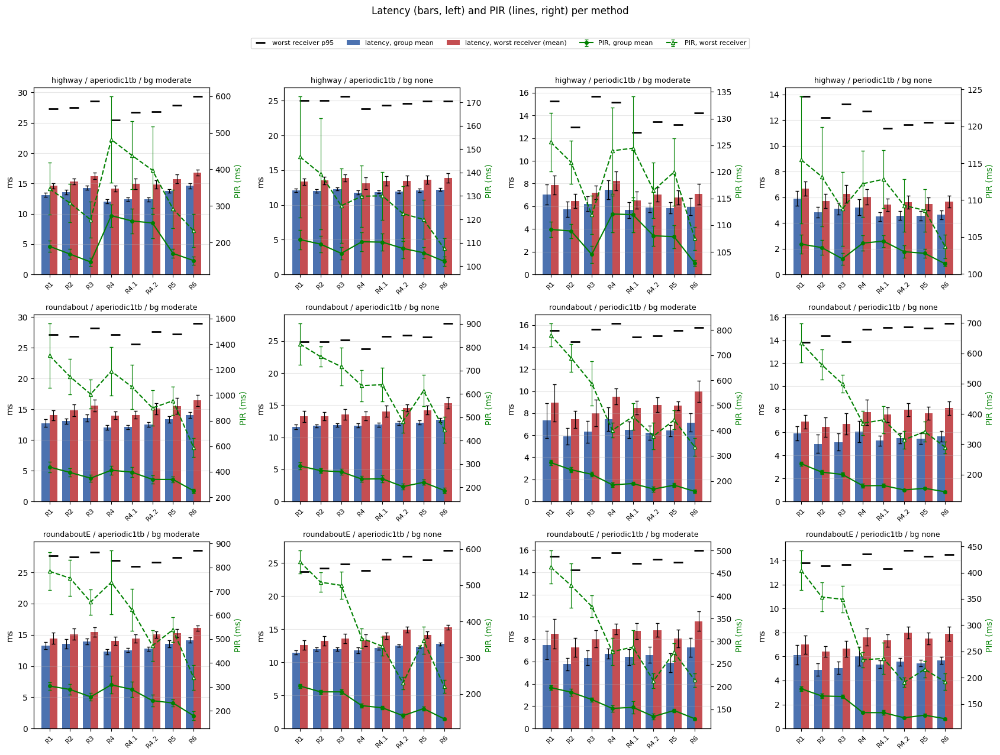

In [57]:
cell_grid(lat_panel, 'Latency (bars, left) and PIR (lines, right) per method')

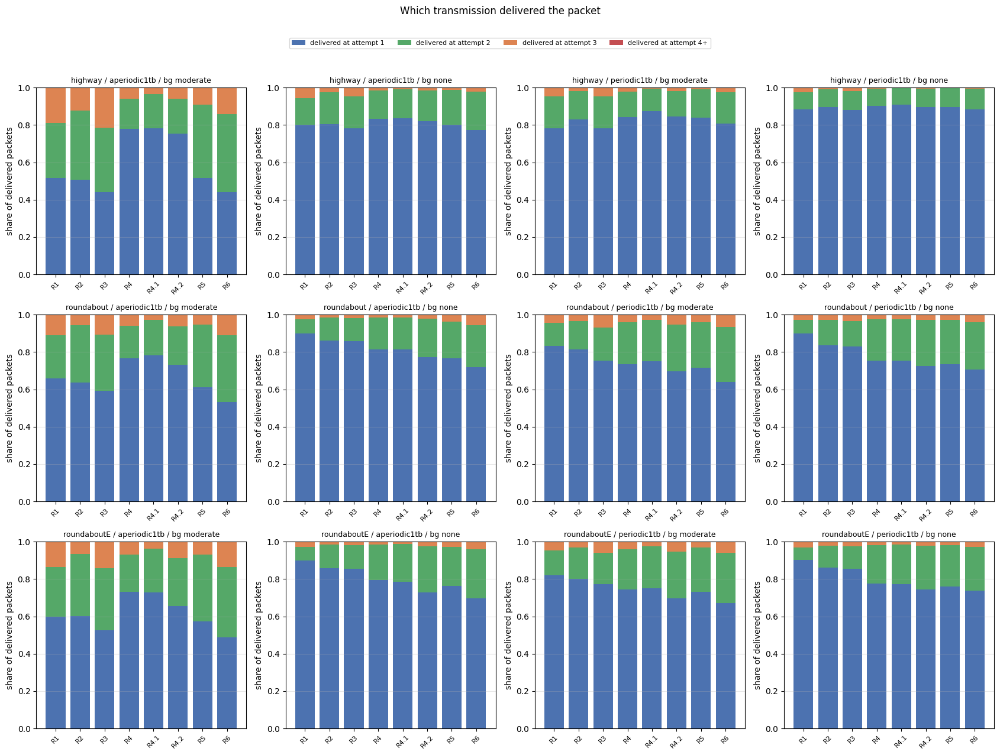

In [58]:
cell_grid(att_panel, 'Which transmission delivered the packet')

In [59]:
ref = {'R1': 'R1', 'R2': 'R1', 'R3': 'R1', 'R4': 'R4', 'R4.1': 'R4', 'R4.2': 'R4', 'R5': 'R4', 'R6': 'R4'}
L = LAT[LAT.arm.isin(ORDER)].set_index(CELLS + ['arm'])
G = []
for (sc, tr, bg, arm), r in L.iterrows():
    b = L.loc[(sc, tr, bg, ref[arm])]
    G.append(dict(scenario=sc, traffic=tr, bg=bg, arm=arm, vs=ref[arm],
        d_lat_group_ms=r.lat_group - b.lat_group, d_lat_worst_ms=r.lat_worst - b.lat_worst,
        d_lat_p95_worst_ms=r.lat_p95_worst - b.lat_p95_worst,
        d_pir_group_ms=r.pir_group - b.pir_group, d_pir_worst_ms=r.pir_worst - b.pir_worst))
LG = pd.DataFrame(G)
display(LAT[LAT.arm.isin(ORDER)].round(2))
LG.round(2)

,scenario,traffic,bg,arm,lat_group,lat_p95_group,lat_worst,lat_p95_worst,late_share,pir_group,pir_worst,pir_p95_worst,pir_max
0,highway,aperiodic1tb,moderate,R1,13.12,24.76,14.61,27.30,0.0,189.50,346.77,869.90,1895.50
2,highway,aperiodic1tb,moderate,R2,13.58,24.97,15.35,27.56,0.0,168.07,307.69,825.61,1455.65
4,highway,aperiodic1tb,moderate,R3,14.28,26.39,16.24,28.59,0.0,146.55,262.15,699.77,1304.35
6,highway,aperiodic1tb,moderate,R4,12.05,21.43,14.14,25.48,0.0,273.48,481.53,1331.59,2710.50
7,highway,aperiodic1tb,moderate,R4.1,12.42,22.46,14.90,26.73,0.0,258.82,438.44,1229.06,2281.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,roundaboutE,periodic1tb,none,R4,6.01,12.60,7.62,14.55,0.0,133.38,234.18,745.80,3993.35
161,roundaboutE,periodic1tb,none,R4.1,5.35,11.35,7.34,13.33,0.0,133.27,236.34,822.22,3938.55
163,roundaboutE,periodic1tb,none,R4.2,5.57,11.45,7.98,14.83,0.0,123.52,190.98,534.29,3824.50
166,roundaboutE,periodic1tb,none,R5,5.45,11.35,7.51,14.34,0.0,128.47,215.89,641.42,4479.10


,scenario,traffic,bg,arm,vs,d_lat_group_ms,d_lat_worst_ms,d_lat_p95_worst_ms,d_pir_group_ms,d_pir_worst_ms
0,highway,aperiodic1tb,moderate,R1,R1,0.00,0.00,0.00,0.00,0.00
1,highway,aperiodic1tb,moderate,R2,R1,0.46,0.74,0.25,-21.43,-39.08
2,highway,aperiodic1tb,moderate,R3,R1,1.16,1.64,1.29,-42.95,-84.62
3,highway,aperiodic1tb,moderate,R4,R4,0.00,0.00,0.00,0.00,0.00
4,highway,aperiodic1tb,moderate,R4.1,R4,0.37,0.76,1.25,-14.66,-43.09
...,...,...,...,...,...,...,...,...,...,...
91,roundaboutE,periodic1tb,none,R4,R4,0.00,0.00,0.00,0.00,0.00
92,roundaboutE,periodic1tb,none,R4.1,R4,-0.66,-0.28,-1.22,-0.11,2.16
93,roundaboutE,periodic1tb,none,R4.2,R4,-0.44,0.37,0.29,-9.86,-43.20
94,roundaboutE,periodic1tb,none,R5,R4,-0.56,-0.11,-0.20,-4.92,-18.29


## Latency CDF with the PRR as ceiling, and age of information
* **Latency CDF**: P(a sent packet reaches a member within t ms), over **all** sent (packet, member) pairs, so dropped packets
  count (they never arrive): the curve saturates at the PRR, and its value at the PDB (dotted line) is the PRR within the PDB.
  Second figure: the worst receiver only (lowest PRR member).
* **Age of information (AoI)**: at each instant, the age of the freshest packet a member holds (now minus its send time).
  It grows linearly between receptions and drops at each fresher reception; a loss lets it keep growing, a late
  retransmission adds its latency. Time-averaged per member; *group* = mean over members, *worst* = largest; peak AoI =
  mean of the age just before each update. Lower is better; it combines latency and loss in one number.

In [60]:

# Latency CDF with the PRR as ceiling, and age of information (AoI), per member, KPI window.
#  CDF: F(t) = P(a sent (packet, member) is received within t ms) over ALL sent pairs: lost packets never
#       arrive, so the curve saturates at the PRR; F(PDB) is the PRR within the PDB.
#  AoI: at time tau a member's age = tau - (send time of the freshest packet it has received); an older
#       packet arriving late does not lower it, a loss lets it grow until the next reception.
#       Time-average over [first reception, end of the KPI window]; peak AoI = age just before each update.
TGRID = np.linspace(0, 100, 401)
cdf_rows, aoi_rows = [], []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    if arm not in ORDER:
        continue
    for p in sorted(glob.glob(armdir + '*_pkt.csv*')):
        tag = os.path.basename(p).split('_pkt.csv')[0]
        cc = cell_of(tag)
        pre = os.path.join(armdir, tag)
        k1 = rd(pre + '_run.csv').iloc[0].kpi_end
        d = rd(pre + '_pkt.csv')
        dl = np.where(d.rx == 1, d.delay_ms, np.inf)
        cdf_all = (dl[:, None] <= TGRID[None, :]).mean(axis=0)
        worst_m = d.groupby('member').rx.mean().idxmin()
        w = d.member == worst_m
        cdf_w = (dl[w.values][:, None] <= TGRID[None, :]).mean(axis=0)
        cdf_rows.append(dict(arm=arm, **cc, cdf=cdf_all, cdf_worst=cdf_w))
        per = []
        for m, g in d[d.rx == 1].groupby('member'):
            t_rx = (g.t_tx + g.delay_ms / 1e3).values
            o = np.argsort(t_rx); t_rx, t_gen = t_rx[o], g.t_tx.values[o]
            fresh = np.maximum.accumulate(t_gen)
            ts = np.append(t_rx, k1)
            area = peak = 0.0; peaks = []
            for i in range(len(t_rx)):
                a0, a1 = t_rx[i] - fresh[i], ts[i + 1] - fresh[i]
                area += (a0 + a1) / 2 * (ts[i + 1] - t_rx[i])
                peaks.append(a1)
            span = k1 - t_rx[0]
            per.append(dict(member=m, aoi=1e3 * area / span if span > 0 else np.nan, peak=1e3 * np.mean(peaks)))
        per = pd.DataFrame(per)
        aoi_rows.append(dict(arm=arm, **cc, aoi_group=per.aoi.mean(), aoi_worst=per.aoi.max(),
                             paoi_group=per.peak.mean(), paoi_worst=per.peak.max()))
CDF = pd.DataFrame(cdf_rows); AOIT = pd.DataFrame(aoi_rows).groupby(CELLS + ['arm']).mean(numeric_only=True).drop(columns='seed').reset_index()
AOICI = mean_ci(pd.DataFrame(aoi_rows), ['aoi_group', 'aoi_worst'], CELLS + ['arm'])

def cdf_panel(which):
    def f(ax, sc, tr, bg):
        d = CDF[(CDF.scenario == sc) & (CDF.traffic == tr) & (CDF.bg == bg)]
        for arm in ORDER:
            g = d[d.arm == arm]
            if len(g):
                col, ls = STYLE[arm]
                st = np.stack(g[which].values)
                mu = st.mean(axis=0)
                ax.plot(TGRID, mu, ls, color=col, lw=1.6, label=LABEL[arm])
                if len(st) > 1:   # 95 % CI over seeds
                    h = stats.t.ppf(0.975, len(st) - 1) * st.std(axis=0, ddof=1) / np.sqrt(len(st))
                    ax.fill_between(TGRID, mu - h, mu + h, color=col, alpha=.12, lw=0)
        ax.axvline(PDB_MS[tr], color='k', lw=.8, ls=':')
        ax.set_xlabel('latency t (ms)'); ax.set_ylabel('P(received within t)'); ax.set_ylim(0, 1.01)
    return f

def aoi_panel(ax, sc, tr, bg):
    d = pick(AOIT, sc, tr, bg); x = np.arange(len(d)); w = .38
    c = pick(AOICI, sc, tr, bg)
    ek = dict(capsize=2, error_kw=dict(lw=.8))
    ax.bar(x - w / 2, d.aoi_group, w, yerr=c.aoi_group_ci, color='#4c72b0', label='AoI, group mean', **ek)
    ax.bar(x + w / 2, d.aoi_worst, w, yerr=c.aoi_worst_ci, color='#c44e52', label='AoI, worst receiver', **ek)
    ax.plot(x + w / 2, d.paoi_worst, 'k_', ms=12, mew=2, label='peak AoI, worst receiver')
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('ms')


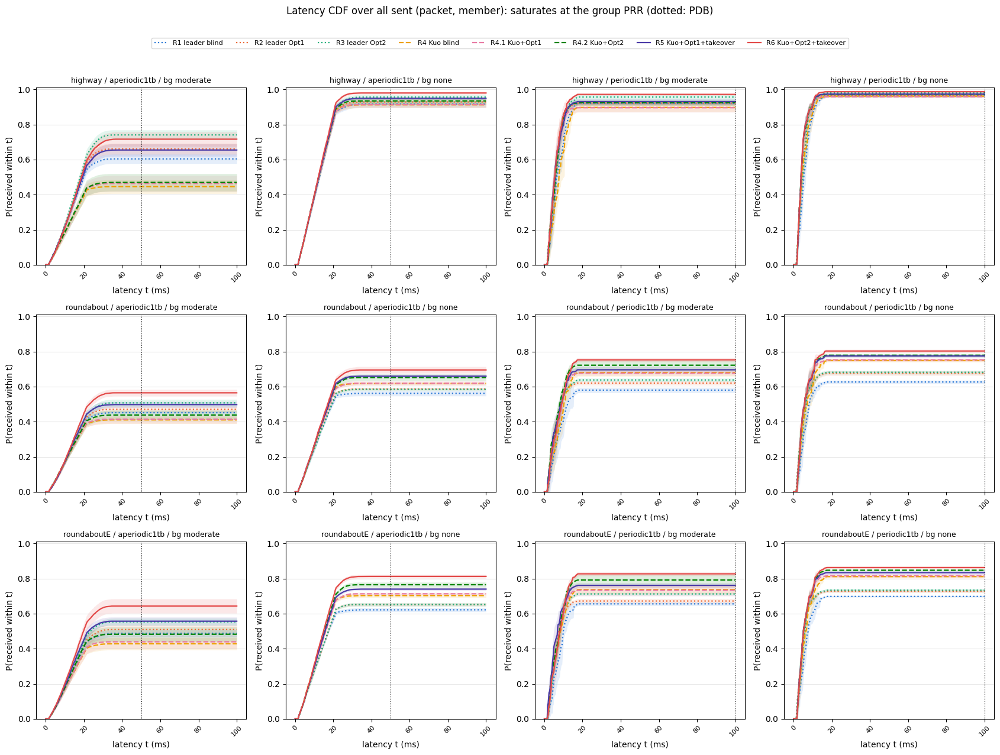

In [61]:
cell_grid(cdf_panel('cdf'), 'Latency CDF over all sent (packet, member): saturates at the group PRR (dotted: PDB)')

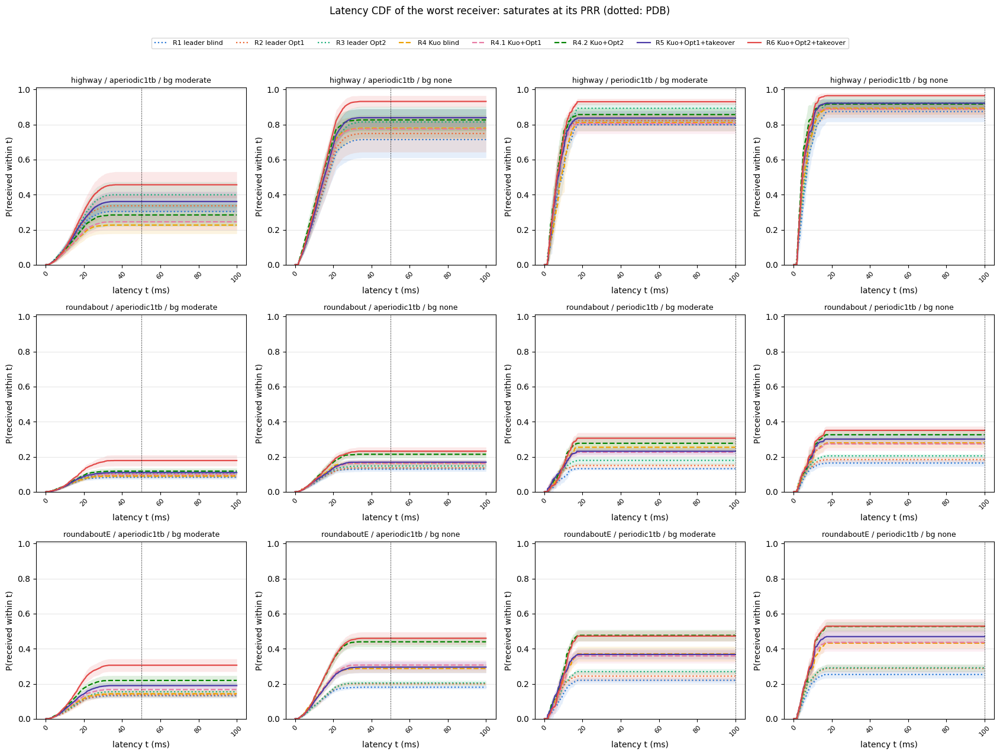

In [62]:
cell_grid(cdf_panel('cdf_worst'), 'Latency CDF of the worst receiver: saturates at its PRR (dotted: PDB)')

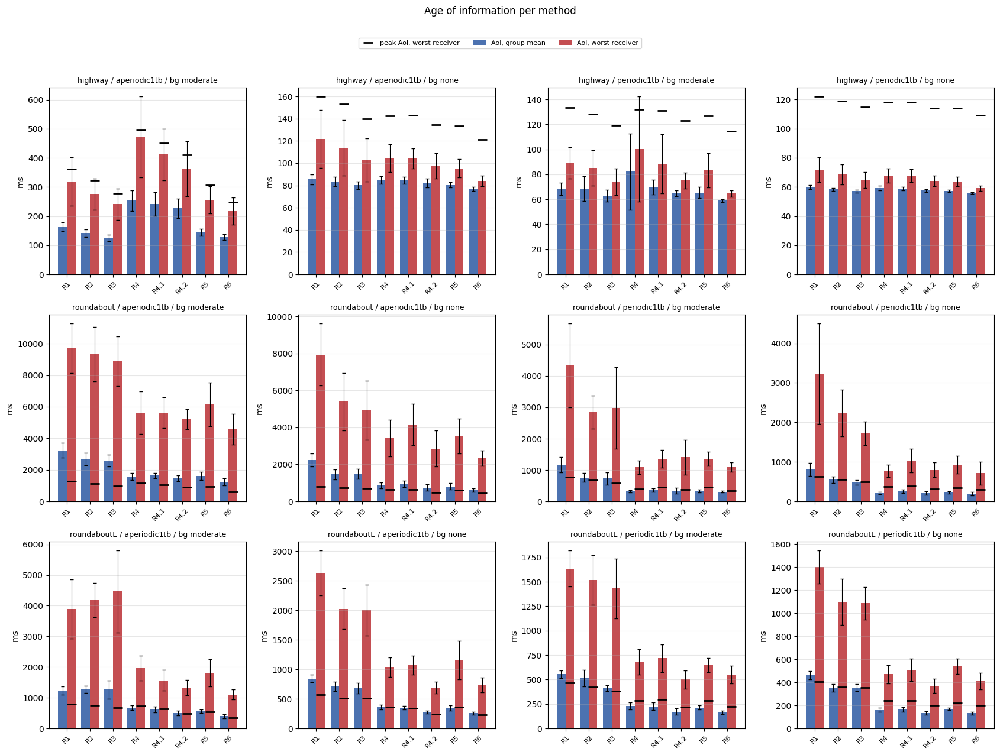

In [63]:
cell_grid(aoi_panel, 'Age of information per method')

In [64]:
AOIT[AOIT.arm.isin(ORDER)].round(1)

,scenario,traffic,bg,arm,aoi_group,aoi_worst,paoi_group,paoi_worst
0,highway,aperiodic1tb,moderate,R1,162.8,319.1,202.8,362.2
1,highway,aperiodic1tb,moderate,R2,141.7,275.8,181.8,323.4
2,highway,aperiodic1tb,moderate,R3,124.8,240.8,161.0,278.2
3,highway,aperiodic1tb,moderate,R4,253.2,471.5,285.9,495.2
4,highway,aperiodic1tb,moderate,R4.1,241.6,411.8,271.0,450.7
...,...,...,...,...,...,...,...,...
91,roundaboutE,periodic1tb,none,R4,160.5,470.0,139.3,240.7
92,roundaboutE,periodic1tb,none,R4.1,163.3,508.1,138.6,242.3
93,roundaboutE,periodic1tb,none,R4.2,134.5,369.5,129.1,198.3
94,roundaboutE,periodic1tb,none,R5,168.3,539.1,133.9,222.5


## Disconnection Time (DT)

**Source.** A. Rolich, M. Yildiz, A. Baiocchi, "Safety-Critical Delays in Vehicular Networks Toward 6G: A Novel Metric for Disconnection Time Assessment", *IEEE Communications Letters*, vol. 30, pp. 1860–1864, 2026, doi:10.1109/LCOMM.2026.3685872 (Sec. III).

**Definition (paper).** The disconnection time $D_{ij}(t)$ of receiver $j$ with respect to transmitter $i$ is the time elapsing between two consecutive successful receptions at $j$ from $i$, *provided that at least one message transmitted by $i$ has been lost to $j$ in between*.

Let $I_1, \dots, I_m$ be the inter-reception intervals at $j$ of messages from $i$ ($I_h = a_h - a_{h-1}$, $a_h$ = reception times), and $I_{j_1}, \dots, I_{j_k}$ ($k \le m$) the subset of intervals that contain at least one lost message. Then

$$\overline{PIR}_{ij} = \frac{1}{m}\sum_{h=1}^{m} I_h, \qquad \overline{DT}_{ij} = \frac{1}{k}\sum_{\ell=1}^{k} I_{j_\ell}.$$

PIR averages over **all** gaps, so at high PRR it is dominated by gaps of one generation period and hides the long outages; DT keeps **only the gaps with a loss**, so it measures how long a receiver stays blind once it loses the flow (e.g. persistent collisions under SPS). The paper reports the mean DT vs transmitter–receiver distance and argues for tail statistics as safety indicators (a 1 s outage every 100 s at PRR 0.99 is invisible in PRR and PIR).

**In this study.** Transmitter $i$ = the platoon leader, receiver $j$ = each member 1..8; a "message" is a leader packet (`_pkt.csv`: one row per packet × member, `rx`, `t_tx`, `delay_ms`). Our leader traffic is one TB per packet (`periodic1tb`: 100 ms; `aperiodic1tb`: 50 ms + Exp(50 ms)), HARQ / helper retransmissions are attempts of the same message, so a message counts as lost only if no copy delivered it. 

**Adaptation agreed for this study (HARQ / helper retransmissions).** The paper assumes broadcast with one transmission per message; here a message can be sent several times (leader retransmissions, helper copies, takeovers). To keep DT a property of the *message flow* and not of the transmissions:

1. **One reception per message.** A message is "received" by member $j$ once, at its **first successful decode** (any copy: initial, retransmission, helper copy). Later copies of an already decoded message are duplicates: they are neither receptions nor gaps (`_pkt.csv` already holds one row per (message, member) with the first-decode delay; the code asserts it). A failed transmission is not a loss as long as some copy of the message is decoded.
2. **Lost message.** Two loss rules, both reported: (a) *never received* (no copy decoded, as PRR); (b) *not received within the PDB* (100 ms periodic, 50 ms aperiodic; a late message counts as lost, as PRR-within-PDB).
3. **Intervals in message order.** Received messages are taken in generation (sequence) order; the interval between two consecutive received messages $p < q$ is a DT sample iff at least one message between them is lost. All intervals (lost or not) give the PIR for comparison.
4. **Two time bases**, both reported: *reception* $DT = a_q - a_p$ ($a$ = first-decode time; the paper's definition, includes the extra delay of a late HARQ / helper recovery) and *generation* $DT = g_q - g_p$ (the loss pattern alone). A reception-based interval can be ≤ 0 if $q$ was delivered before $p$ (out of order); such samples are counted and reported.
5. **KPI window edges.** Losses before the first or after the last reception of a member in the KPI window are censored outages: dropped from DT (paper: a sample needs two receptions), their number is reported.
6. **Statistics** per run, then mean ± 95 % CI over the 10 seeds: mean DT (per member, averaged over members), worst-member mean DT, p95 and max over all DT samples of the run, P(DT > 300 ms) and P(DT > 1 s) over the DT samples, and the mean DT vs leader–member distance (the paper's Fig. 4).


In [65]:
# Disconnection Time (DT) per (run, member), 4 variants: time base {rx, gen} x loss rule {lost, pdb}.
# See the definition cell above; one reception per message = first decode (no duplicates).
DT_ARMS = [a for a in ORDER + ['R1_bsc', 'R4_bsc'] if os.path.isdir(os.path.join(OUT, a))]
DT_VARIANTS = [(tb, lr) for tb in ('rx', 'gen') for lr in ('lost', 'pdb')]
THETAS_MS = (300.0, 1000.0)

def dt_samples(g, pdb_ms, base, rule):
    """g: one member's messages in the KPI window (one row per seq). Returns (DT samples ms, PIR samples ms,
    censored outages, out-of-order intervals)."""
    g = g.sort_values('seq')
    ok = (g.rx.values == 1) if rule == 'lost' else ((g.rx.values == 1) & (g.delay_ms.values <= pdb_ms))
    pos = np.flatnonzero(ok)
    if len(pos) < 2:
        return np.array([]), np.array([]), int((~ok).any()), 0
    t = g.t_tx.values * 1e3 + (g.delay_ms.values if base == 'rx' else 0.0)
    gaps = np.diff(t[pos])
    lost_between = np.diff(pos) > 1
    censored = int(pos[0] > 0) + int(pos[-1] < len(ok) - 1)
    return gaps[lost_between], gaps, censored, int((gaps <= 0).sum())

dt_rows, dtm_rows = [], []
for arm in DT_ARMS:
    for p in sorted(glob.glob(os.path.join(OUT, arm, '*_pkt.csv*'))):
        tag = os.path.basename(p).split('_pkt.csv')[0]
        cc = cell_of(tag)
        d = rd(os.path.join(OUT, arm, tag) + '_pkt.csv')[['seq', 't_tx', 'member', 'rx', 'delay_ms', 'dist_m']]
        assert not d.duplicated(['seq', 'member']).any(), f'duplicate (message, member) rows in {arm}/{tag}'
        pdb = PDB_MS[cc['traffic']]
        for base, rule in DT_VARIANTS:
            pooled, per_m, cens, ooo = [], [], 0, 0
            for m, g in d.groupby('member'):
                s, pir, c, o = dt_samples(g, pdb, base, rule)
                cens += c; ooo += o
                pooled.append(s)
                per_m.append(dict(member=m, dt_mean=s.mean() if len(s) else np.nan, n_dt=len(s),
                                  pir_mean=pir.mean() if len(pir) else np.nan, dist=g.dist_m.mean()))
                dtm_rows.append(dict(arm=arm, **cc, base=base, rule=rule, member=m, dist=g.dist_m.mean(),
                                     dt_mean=per_m[-1]['dt_mean'], n_dt=len(s)))
            s = np.concatenate(pooled) if pooled else np.array([])
            pm = pd.DataFrame(per_m)
            dt_rows.append(dict(arm=arm, **cc, base=base, rule=rule,
                                dt_mean=pm.dt_mean.mean(),            # members without any outage are skipped
                                dt_worst=pm.dt_mean.max(),
                                dt_p95=np.percentile(s, 95) if len(s) else np.nan,
                                dt_max=s.max() if len(s) else np.nan,
                                p_dt_300=(s > THETAS_MS[0]).mean() if len(s) else np.nan,
                                p_dt_1000=(s > THETAS_MS[1]).mean() if len(s) else np.nan,
                                n_dt=len(s), pir_mean=pm.pir_mean.mean(), censored=cens, out_of_order=ooo))
DT = pd.DataFrame(dt_rows); DTM = pd.DataFrame(dtm_rows)
DT_COLS = ['dt_mean', 'dt_worst', 'dt_p95', 'dt_max', 'p_dt_300', 'p_dt_1000', 'pir_mean']
DTCI = mean_ci(DT, DT_COLS + ['n_dt', 'censored', 'out_of_order'], CELLS + ['base', 'rule', 'arm'])
print(f"{len(DT) // len(DT_VARIANTS)} runs x {len(DT_VARIANTS)} variants; arms {DT_ARMS}")
print('out-of-order reception intervals (rx base):', int(DT[DT.base == 'rx'].out_of_order.sum()),
      '| censored outages dropped:', int(DT[(DT.base == 'rx') & (DT.rule == 'lost')].censored.sum()))


1200 runs x 4 variants; arms ['R1', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6', 'R1_bsc', 'R4_bsc']
out-of-order reception intervals (rx base): 0 | censored outages dropped: 1836


In [66]:
# DT summary (mean over seeds; +- = 95 % CI). Default view: reception time base, "never received" loss rule
# (the paper's definition); the other three variants are in DTCI (filter base / rule).
def dt_table(base='rx', rule='lost', cols=('dt_mean', 'dt_worst', 'dt_p95', 'dt_max', 'p_dt_300', 'p_dt_1000', 'pir_mean')):
    t = DTCI[(DTCI.base == base) & (DTCI.rule == rule)].copy()
    t['arm'] = pd.Categorical(t.arm, DT_ARMS)
    out = t.sort_values(CELLS + ['arm'])[CELLS + ['arm']].copy()
    for c in cols:
        prec = 3 if c.startswith('p_') else 0
        out[c] = t[c].round(prec).astype(str) + ' ±' + t[c + '_ci'].round(prec).astype(str)
    return out.set_index(CELLS + ['arm'])

display(dt_table('rx', 'lost'))
# the four variants side by side for the mean DT (ms)
v = DTCI.pivot_table(index=CELLS + ['arm'], columns=['base', 'rule'], values='dt_mean').round(0)
v = v.reindex([i for i in v.index if i[3] in DT_ARMS]); v


dt_mean       dt_worst         dt_p95         dt_max      p_dt_300     p_dt_1000     pir_mean
scenario    traffic      bg       arm                                                                                                      
highway     aperiodic1tb moderate R1      282.0 ±16.0    431.0 ±69.0    629.0 ±46.0  1895.0 ±586.0  0.337 ±0.027   0.01 ±0.004  190.0 ±15.0
                                  R2      263.0 ±16.0    400.0 ±56.0    580.0 ±52.0  1456.0 ±298.0  0.299 ±0.029  0.007 ±0.004  168.0 ±14.0
                                  R3      245.0 ±12.0    361.0 ±56.0    555.0 ±55.0  1304.0 ±246.0    0.27 ±0.03  0.007 ±0.004  147.0 ±11.0
                                  R4      372.0 ±33.0   576.0 ±112.0    918.0 ±99.0  2711.0 ±760.0  0.451 ±0.029  0.039 ±0.013  273.0 ±31.0
                                  R4.1    358.0 ±31.0    528.0 ±86.0   882.0 ±114.0  2281.0 ±526.0  0.434 ±0.031  0.035 ±0.015  259.0 ±34.0
...                                               ...            ...            ...            ...           ...           ...          ...
roundaboutE periodic1tb  none     R4.2    310.0 ±11.0    457.0 ±29.0   869.0 ±104.0  3825.0 ±531.0  0.307 ±0.036  0.043 ±0.009   124.0 ±1.0
                                  R5      344.0 ±19.0    561.0 ±56.0  1148.0 ±142.0  4479.0 ±350.0  0.321 ±0.035  0.064 ±0.015   128.0 ±3.0
                                  R6      318.0 ±17.0    467.0 ±29.0   953.0 ±153.0  3829.0 ±765.0  0.299 ±0.015  0.052 ±0.015   122.0 ±2.0
                                  R1_bsc  599.0 ±51.0  1189.0 ±138.0  2590.0 ±350.0  5969.0 ±395.0  0.486 ±0.025  0.161 ±0.033   162.0 ±5.0
                                  R4_bsc  333.0 ±18.0    506.0 ±38.0   985.0 ±128.0  4160.0 ±684.0  0.336 ±0.023   0.05 ±0.012   131.0 ±2.0

[120 rows x 7 columns]

base                                        gen            rx       
rule                                       lost    pdb   lost    pdb
scenario    traffic      bg       arm                               
highway     aperiodic1tb moderate R1      282.0  282.0  282.0  282.0
                                  R1_bsc  261.0  261.0  261.0  261.0
                                  R2      263.0  263.0  263.0  263.0
                                  R3      245.0  245.0  245.0  245.0
                                  R4      372.0  372.0  372.0  372.0
...                                         ...    ...    ...    ...
roundaboutE periodic1tb  none     R4.1    336.0  336.0  336.0  336.0
                                  R4.2    310.0  310.0  310.0  310.0
                                  R4_bsc  333.0  333.0  333.0  333.0
                                  R5      344.0  344.0  344.0  344.0
                                  R6      318.0  318.0  318.0  318.0

[120 rows x 4 columns]

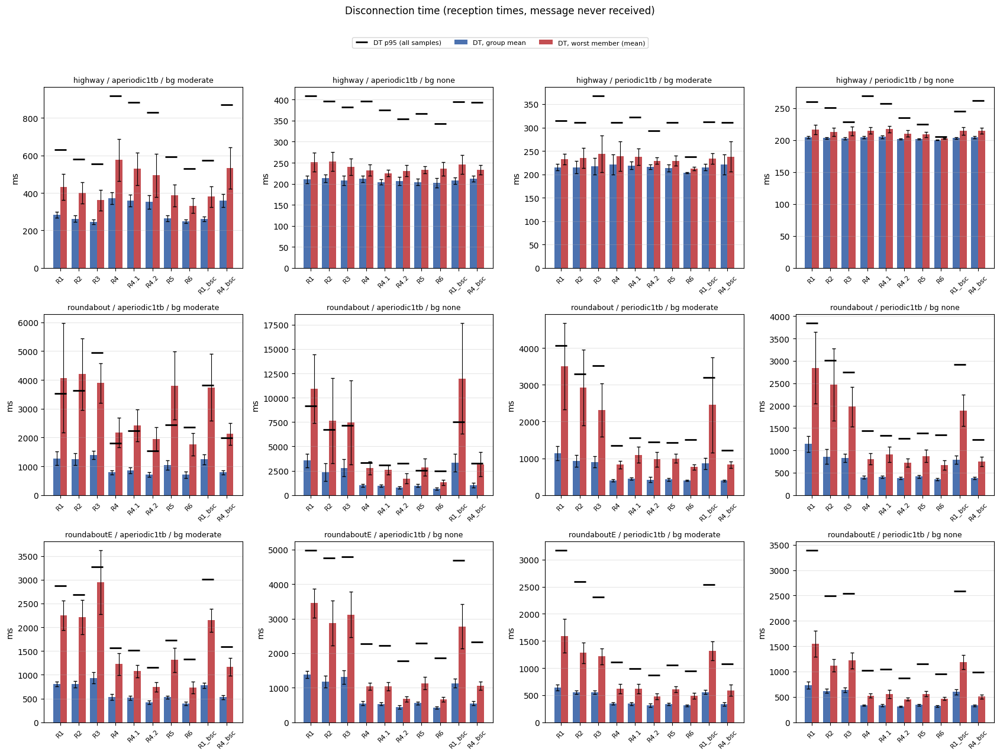

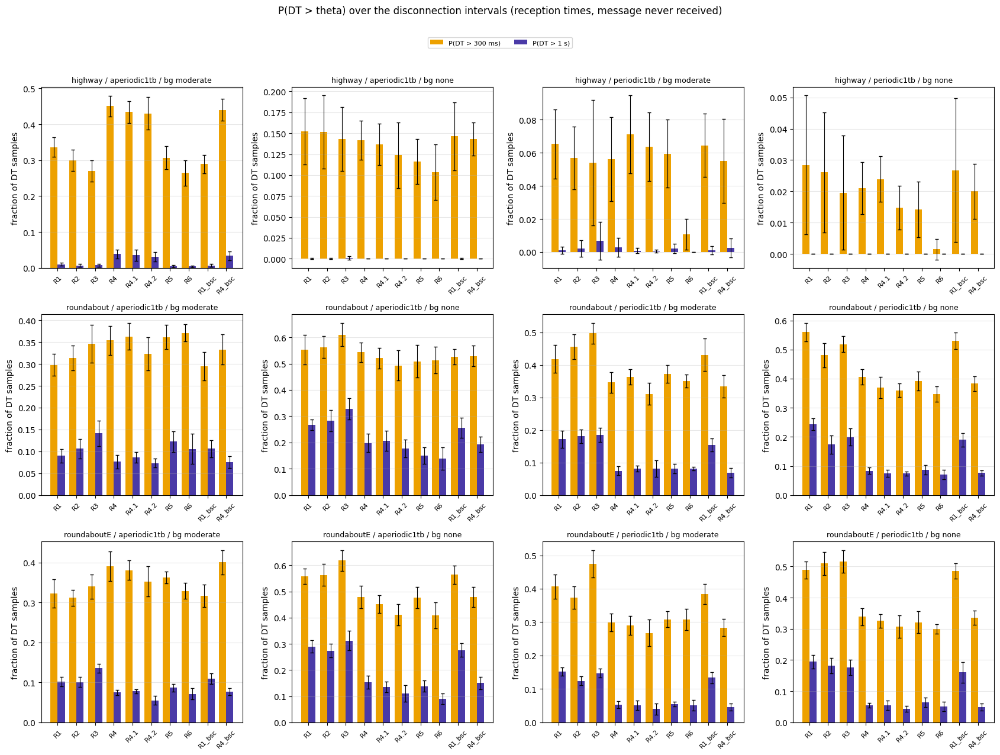

In [67]:
# DT bars per cell: group mean, worst member (95 % CI over seeds), p95 marker; second figure: P(DT > theta)
def dt_panel(base, rule):
    def f(ax, sc, tr, bg):
        d = DTCI[(DTCI.base == base) & (DTCI.rule == rule) & (DTCI.scenario == sc) & (DTCI.traffic == tr) &
                 (DTCI.bg == bg)].set_index('arm').reindex([a for a in DT_ARMS if a in set(DTCI.arm)])
        x = np.arange(len(d)); w = .38; ek = dict(capsize=2, error_kw=dict(lw=.8))
        ax.bar(x - w / 2, d.dt_mean, w, yerr=d.dt_mean_ci, color='#4c72b0', label='DT, group mean', **ek)
        ax.bar(x + w / 2, d.dt_worst, w, yerr=d.dt_worst_ci, color='#c44e52', label='DT, worst member (mean)', **ek)
        ax.plot(x, d.dt_p95, 'k_', ms=14, mew=2, label='DT p95 (all samples)')
        ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('ms')
    return f

def pdt_panel(base, rule):
    def f(ax, sc, tr, bg):
        d = DTCI[(DTCI.base == base) & (DTCI.rule == rule) & (DTCI.scenario == sc) & (DTCI.traffic == tr) &
                 (DTCI.bg == bg)].set_index('arm').reindex([a for a in DT_ARMS if a in set(DTCI.arm)])
        x = np.arange(len(d)); w = .38; ek = dict(capsize=2, error_kw=dict(lw=.8))
        ax.bar(x - w / 2, d.p_dt_300, w, yerr=d.p_dt_300_ci, color='#eda100', label='P(DT > 300 ms)', **ek)
        ax.bar(x + w / 2, d.p_dt_1000, w, yerr=d.p_dt_1000_ci, color='#4a3aa7', label='P(DT > 1 s)', **ek)
        ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('fraction of DT samples')
    return f

cell_grid(dt_panel('rx', 'lost'), 'Disconnection time (reception times, message never received)')
cell_grid(pdt_panel('rx', 'lost'), 'P(DT > theta) over the disconnection intervals (reception times, message never received)')


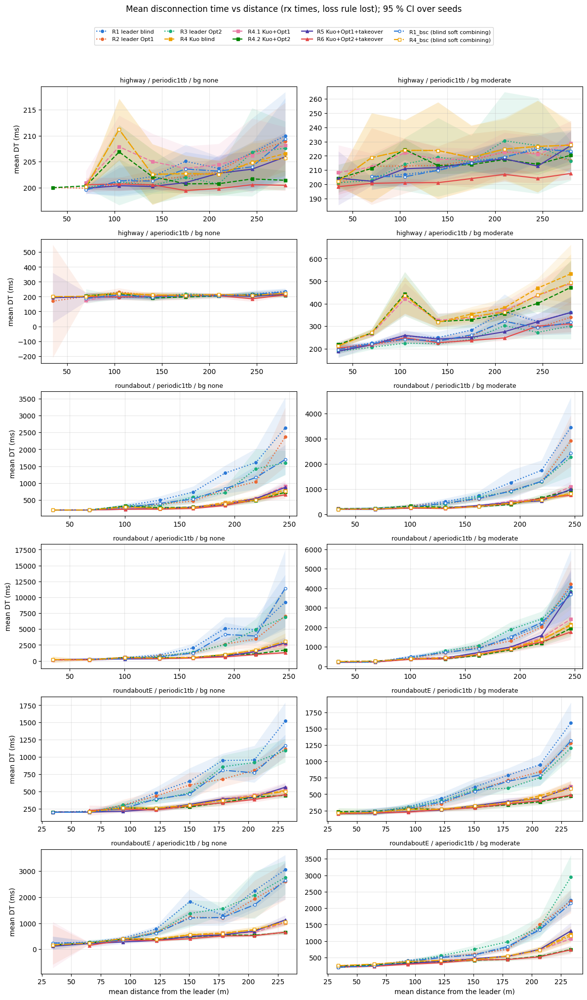

In [68]:
# Mean DT vs leader-member distance (the paper's Fig. 4): per member, mean over seeds (95 % CI shaded)
def dt_dist_plot(base='rx', rule='lost', arms=None):
    arms = arms or DT_ARMS
    scen = [s for s in ['highway', 'roundabout', 'roundaboutE'] if s in set(DTM.scenario)]
    trafs, bgs = ['periodic1tb', 'aperiodic1tb'], ['none', 'moderate']
    D = DTM[(DTM.base == base) & (DTM.rule == rule)]
    fig, axes = plt.subplots(len(scen) * len(trafs), len(bgs), figsize=(12, 3.3 * len(scen) * len(trafs)), squeeze=False)
    for i, (sc, tr) in enumerate([(s, t) for s in scen for t in trafs]):
        for j, bg in enumerate(bgs):
            ax = axes[i, j]
            d = D[(D.scenario == sc) & (D.traffic == tr) & (D.bg == bg)]
            for arm in arms:
                g = mean_ci(d[d.arm == arm], ['dist', 'dt_mean'], 'member').sort_values('dist')
                if len(g):
                    col, ls = STYLE[arm.replace('_bsc', '')]
                    bsc = arm.endswith('_bsc')
                    ax.plot(g.dist, g.dt_mean, '-.' if bsc else ls, color=col, lw=1.6, marker=MARK[ls], ms=4,
                            mfc='white' if bsc else col, label=LABEL.get(arm, arm + ' (blind soft combining)'))
                    ax.fill_between(g.dist, g.dt_mean - g.dt_mean_ci, g.dt_mean + g.dt_mean_ci, color=col, alpha=.10, lw=0)
            ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9); ax.grid(alpha=.3)
            if j == 0: ax.set_ylabel('mean DT (ms)')
            if i == len(scen) * len(trafs) - 1: ax.set_xlabel('mean distance from the leader (m)')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=min(len(h), 5), fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f'Mean disconnection time vs distance ({base} times, loss rule {rule}); 95 % CI over seeds', y=1.02)
    fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

dt_dist_plot('rx', 'lost')


## HARQ-IR (soft-combining) gain
Arm with soft combining minus the same arm with every copy decoded independently, on the arms without helper takeover.

,scenario,traffic,bg,arm,prr_IR,prr_noIR,gain_prr,gain_prr_worst,tx_per_pkt_IR,tx_per_pkt_noIR
0,highway,aperiodic1tb,moderate,R2,0.6613,0.6119,0.0494,0.0523,12.2732,12.9914
1,highway,aperiodic1tb,moderate,R3,0.7406,0.6726,0.0679,0.0657,13.9436,14.1748
2,highway,aperiodic1tb,moderate,R4.1,0.4636,0.4429,0.0207,0.0359,7.0204,7.2999
3,highway,aperiodic1tb,moderate,R4.2,0.4697,0.4657,0.0041,0.0229,7.4749,7.7853
4,highway,aperiodic1tb,none,R2,0.9288,0.9209,0.0079,0.0303,10.4009,11.0964
5,highway,aperiodic1tb,none,R3,0.9564,0.9411,0.0153,0.0543,11.8469,12.4474
6,highway,aperiodic1tb,none,R4.1,0.9134,0.9105,0.0028,0.0057,8.5962,8.8533
7,highway,aperiodic1tb,none,R4.2,0.9346,0.9335,0.0012,0.0062,9.8133,10.1201
8,highway,periodic1tb,moderate,R2,0.9219,0.9125,0.0094,0.0191,3.5718,3.6666
9,highway,periodic1tb,moderate,R3,0.9567,0.9548,0.0019,0.0085,4.2455,4.2992


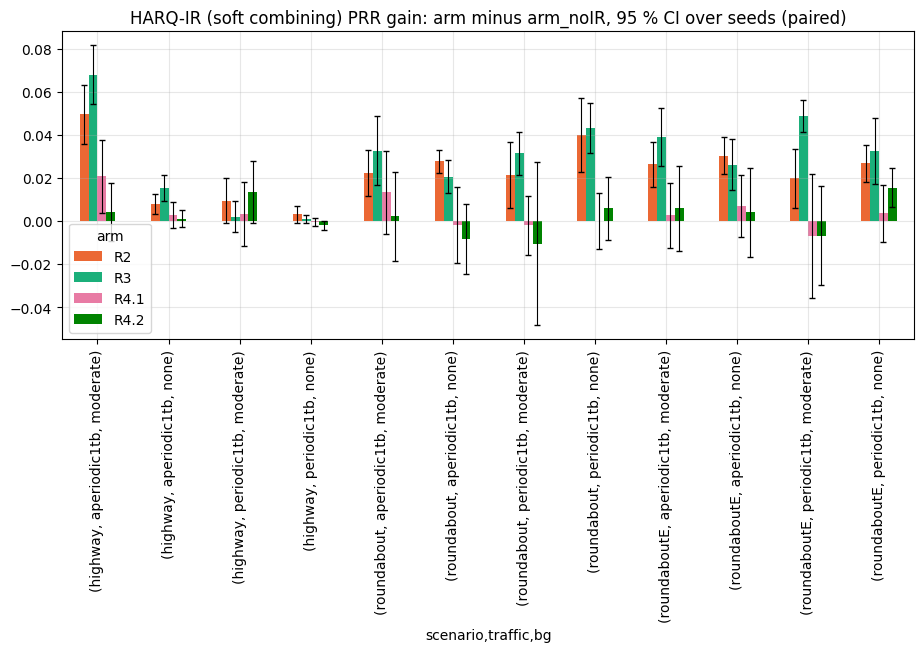

In [69]:

rows = []
for (sc, tr, bg), g in agg.groupby(CELLS):
    g = g.set_index('arm')
    for arm in ['R2', 'R3', 'R4.1', 'R4.2']:
        if arm in g.index and arm + '_noIR' in g.index:
            a, b = g.loc[arm], g.loc[arm + '_noIR']
            rows.append(dict(scenario=sc, traffic=tr, bg=bg, arm=arm, prr_IR=a.prr, prr_noIR=b.prr,
                             gain_prr=a.prr - b.prr, gain_prr_worst=a.prr_worst - b.prr_worst,
                             tx_per_pkt_IR=a.tx_per_pkt, tx_per_pkt_noIR=b.tx_per_pkt))
IRG = pd.DataFrame(rows)
display(IRG.round(4))
if len(IRG):
    # paired per seed: arm minus arm_noIR in the same seed, mean and 95 % CI over seeds
    Rp = R.set_index(CELLS + ['seed', 'arm']).prr
    gr = [dict(scenario=sc, traffic=tr, bg=bg, arm=a, g=v - Rp.get((sc, tr, bg, sd, a + '_noIR'), np.nan))
          for (sc, tr, bg, sd, a), v in Rp.items() if a in ('R2', 'R3', 'R4.1', 'R4.2')]
    gc = mean_ci(pd.DataFrame(gr), ['g'], CELLS + ['arm'])
    arms = [a for a in ['R2', 'R3', 'R4.1', 'R4.2'] if a in set(gc.arm)]
    p = gc.pivot_table(index=CELLS, columns='arm', values='g')[arms]
    e = gc.pivot_table(index=CELLS, columns='arm', values='g_ci')[arms]
    p.plot.bar(yerr=e, capsize=2, figsize=(11, 4), color=[STYLE[a][0] for a in arms], error_kw=dict(lw=.8),
               title='HARQ-IR (soft combining) PRR gain: arm minus arm_noIR, 95 % CI over seeds (paired)')
    plt.grid(alpha=.3); plt.show()


## Helper takeover (R5 / R6): helper NACKs, leader fallback, PRR gain
* `helper_nack`: NACKs of the named helper received by the leader (each lets it retake a handed slot; `helper_reclaim`).
* `fallback_check`: handed slots in which a relay was expected; `fallback_heard`: the leader decoded the helper's SCI there;
  `fallback_tx`: nothing heard, the leader retransmitted in the next handed slot; `fallback_no_slot`: nothing heard, no slot left.
* `recovered_*`: member-packets first delivered by those leader retransmissions (PRR points attributable to each mechanism).
* `d_prr_vs_no_takeover`: R5 - R4.1 and R6 - R4.2 (whole takeover effect, including retransmission timing).

,scenario,traffic,bg,arm,helper_nack,helper_reclaim,fallback_check,fallback_heard,fallback_tx,fallback_no_slot,recovered_nack,recovered_fallback,d_prr_vs_no_takeover,d_prr_worst_vs_no_takeover
0,highway,aperiodic1tb,moderate,R5,305.6,275.5,351.5,227.6,97.2,26.7,0.1402,0.0369,0.1909,0.1156
1,highway,aperiodic1tb,moderate,R6,327.3,271.2,433.5,263.6,126.3,43.6,0.1575,0.0633,0.2467,0.1721
2,highway,aperiodic1tb,none,R5,69.3,67.6,379.7,370.8,8.3,0.5,0.0308,0.0026,0.0357,0.0645
3,highway,aperiodic1tb,none,R6,70.2,67.8,420.9,410.3,9.8,0.8,0.0341,0.0036,0.0452,0.1054
4,highway,periodic1tb,moderate,R5,46.7,45.7,301.1,283.8,16.2,1.1,0.0246,0.0053,0.0347,0.0312
5,highway,periodic1tb,moderate,R6,47.0,45.0,354.0,338.0,14.3,1.7,0.0300,0.0090,0.0464,0.0732
6,highway,periodic1tb,none,R5,30.0,29.8,267.3,263.4,3.7,0.2,0.0113,0.0006,0.0148,0.0338
7,highway,periodic1tb,none,R6,30.9,30.2,314.0,308.2,5.4,0.4,0.0125,0.0012,0.0151,0.0479
8,roundabout,aperiodic1tb,moderate,R5,141.3,120.2,369.1,293.5,64.6,11.0,0.0741,0.0169,0.0832,0.0091
9,roundabout,aperiodic1tb,moderate,R6,152.2,125.1,445.8,350.1,71.0,24.7,0.0868,0.0250,0.1268,0.0603


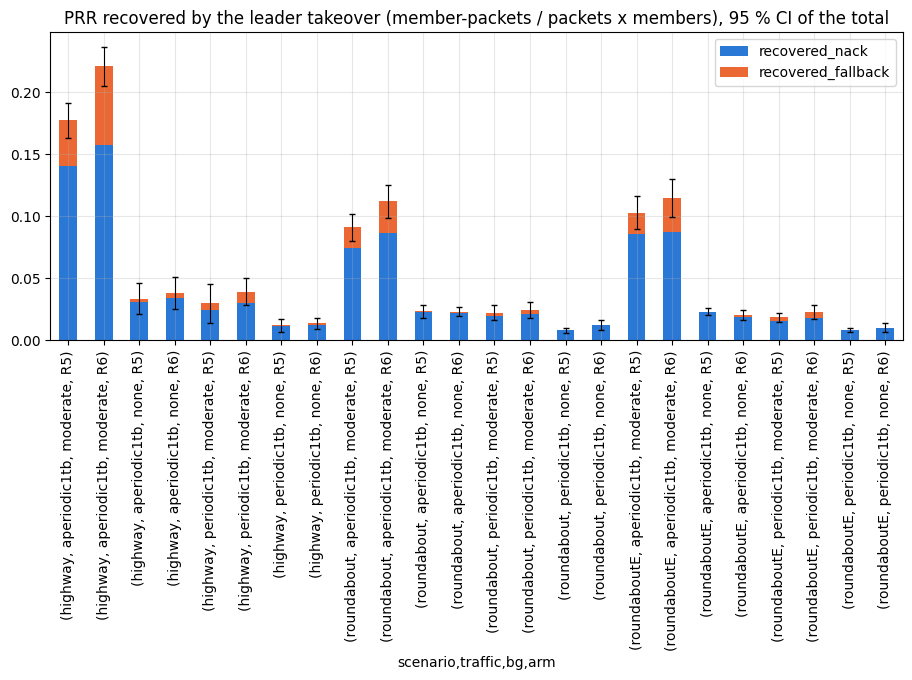

In [70]:

tk = R[R.arm.isin(['R5', 'R6'])].groupby(CELLS + ['arm']).agg(
        helper_nack=('helper_nack', 'mean'), helper_reclaim=('helper_reclaim', 'mean'),
        fallback_check=('fallback_check', 'mean'), fallback_heard=('fallback_heard', 'mean'),
        fallback_tx=('fallback_tx', 'mean'), fallback_no_slot=('fallback_no_slot', 'mean'),
        recovered_nack=('recovered_nack', 'mean'), recovered_fallback=('recovered_fallback', 'mean')).reset_index()
base = {'R5': 'R4.1', 'R6': 'R4.2'}
a = agg.set_index(CELLS + ['arm'])
tk['d_prr_vs_no_takeover'] = [a.prr.get((r.scenario, r.traffic, r.bg, r.arm), np.nan) -
                              a.prr.get((r.scenario, r.traffic, r.bg, base[r.arm]), np.nan) for r in tk.itertuples()]
tk['d_prr_worst_vs_no_takeover'] = [a.prr_worst.get((r.scenario, r.traffic, r.bg, r.arm), np.nan) -
                                    a.prr_worst.get((r.scenario, r.traffic, r.bg, base[r.arm]), np.nan) for r in tk.itertuples()]
display(tk.round(4))
x = tk.set_index(CELLS + ['arm'])[['recovered_nack', 'recovered_fallback']]
ax = x.plot.bar(stacked=True, figsize=(11, 4), color=['#2a78d6', '#eb6834'],
                title='PRR recovered by the leader takeover (member-packets / packets x members), 95 % CI of the total')
tc = mean_ci(R[R.arm.isin(['R5', 'R6'])].assign(t=lambda r: r.recovered_nack + r.recovered_fallback), ['t'],
             CELLS + ['arm']).set_index(CELLS + ['arm']).reindex(x.index)
ax.errorbar(np.arange(len(x)), x.sum(axis=1).values, yerr=tc.t_ci.values, fmt='none', ecolor='k', elinewidth=.8, capsize=2)
plt.grid(alpha=.3); plt.show()
